# IBM HR Analytics Employee Attrition

This notebook evaluates individual and voting classifiers with ReliefF and MultiSURF on the IBM HR Analytics dataset. It includes preprocessing, fold-local feature selection and SMOTE, feature-count optimisation, holdout evaluation, three-seed stability analysis, and SHAP interpretation.

**Evaluation protocol**
- Seed 42 is used for the stratified 80/20 split and the main five-fold cross-validation.
- Target encoding, scaling, feature ranking, and SMOTE are fitted using training-fold data only.
- The feature count is selected by mean cross-validation F1.
- The untouched holdout set is used for the final descriptive comparison.
- Seeds 42, 43, and 44 assess the stability of the selected voting configuration.

This copy retains the original preprocessing, classifiers, parameter grids,
and fold-specific ranking. Training CV selects the final configuration.
An all-features baseline uses the original input column order. Selector
runs retain their original ranking order, including at the full count.
Stochastic models can therefore produce different predictions even when
the feature set is identical. Full-count rows represent the same predictors,
and do not demonstrate feature reduction.

The existing holdout was examined during earlier analyses. Results on it
are internal descriptive comparisons. Bootstrap intervals condition on
the fitted model and this split. The fixed-configuration seed analysis
covers voting classifiers and does not assess the complete selection
procedure. Saudi labels concern previous attrition.


## Import Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from scipy.stats import zscore
from sklearn.preprocessing import MinMaxScaler, LabelEncoder, OrdinalEncoder
import warnings
warnings.filterwarnings('ignore')

sns.set(style="whitegrid", palette="Set2", font_scale=1.2)


## Load Dataset & Overview

In [2]:
# Load Dataset - Handle quoted CSV lines and BOM encoding
import io

file_path = "WA_Fn-UseC_-HR-Employee-Attrition.csv"

# Read raw file with utf-8-sig to handle BOM
with open(file_path, 'r', encoding='utf-8-sig') as f:
    lines = f.readlines()

# Remove the enclosing quotes from each line
cleaned_lines = []
for line in lines:
    line = line.strip()
    if line.startswith('"') and line.endswith('"'):
        line = line[1:-1]  # Remove first and last quote
    cleaned_lines.append(line)

# Create CSV from cleaned lines
cleaned_csv = '\n'.join(cleaned_lines)
df = pd.read_csv(io.StringIO(cleaned_csv))

print("="*60)
print("DATASET OVERVIEW")
print("="*60)
print(f"Total Rows: {df.shape[0]}")
print(f"Total Columns: {df.shape[1]}")
print(f"\nColumn Names:\n{df.columns.tolist()}")

print("\n" + "="*60)
print("DATA TYPES")
print("="*60)
df.info()

df.head()


DATASET OVERVIEW
Total Rows: 1470
Total Columns: 35

Column Names:
['Age', 'Attrition', 'BusinessTravel', 'DailyRate', 'Department', 'DistanceFromHome', 'Education', 'EducationField', 'EmployeeCount', 'EmployeeNumber', 'EnvironmentSatisfaction', 'Gender', 'HourlyRate', 'JobInvolvement', 'JobLevel', 'JobRole', 'JobSatisfaction', 'MaritalStatus', 'MonthlyIncome', 'MonthlyRate', 'NumCompaniesWorked', 'Over18', 'OverTime', 'PercentSalaryHike', 'PerformanceRating', 'RelationshipSatisfaction', 'StandardHours', 'StockOptionLevel', 'TotalWorkingYears', 'TrainingTimesLastYear', 'WorkLifeBalance', 'YearsAtCompany', 'YearsInCurrentRole', 'YearsSinceLastPromotion', 'YearsWithCurrManager']

DATA TYPES
<class 'pandas.DataFrame'>
RangeIndex: 1470 entries, 0 to 1469
Data columns (total 35 columns):
 #   Column                    Non-Null Count  Dtype
---  ------                    --------------  -----
 0   Age                       1470 non-null   int64
 1   Attrition                 1470 non-null   

,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,...,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,...,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,...,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,...,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,...,4,80,1,6,3,3,2,2,2,2


## Missing Values Analysis

In [3]:
# Missing Values Analysis
print("="*60)
print("MISSING VALUES ANALYSIS")
print("="*60)

missing_values = df.isnull().sum()
missing_percent = (missing_values / len(df)) * 100
missing_df = pd.DataFrame({
    'Missing Count': missing_values,
    'Missing %': missing_percent
})

if missing_values.sum() == 0:
    print("✓ No missing values found in the dataset!")
else:
    print(missing_df[missing_df['Missing Count'] > 0])

print(f"\nTotal missing values: {missing_values.sum()}")


MISSING VALUES ANALYSIS
✓ No missing values found in the dataset!

Total missing values: 0


## Data Cleaning: Remove Constant Columns & Analyze Unique Values

In [4]:
# Remove Constant/Useless Columns
# EmployeeCount (all=1), StandardHours (all=80), Over18 (all='Y'), EmployeeNumber (unique ID)

print("="*60)
print("REMOVING CONSTANT/USELESS COLUMNS")
print("="*60)

# Check values before dropping
print("\nColumns to remove:")
print(f"  - EmployeeCount unique values: {df['EmployeeCount'].unique()}")
print(f"  - StandardHours unique values: {df['StandardHours'].unique()}")
print(f"  - Over18 unique values: {df['Over18'].unique()}")
print(f"  - EmployeeNumber: Unique ID (not useful for prediction)")

cols_to_drop = ['EmployeeCount', 'StandardHours', 'Over18', 'EmployeeNumber']
df = df.drop(columns=cols_to_drop)

print(f"\n✓ Dropped {len(cols_to_drop)} columns")
print(f"Remaining columns: {df.shape[1]}")

# Unique Values Analysis
print("\n" + "="*60)
print("UNIQUE VALUES PER COLUMN")
print("="*60)

for col in df.columns:
    n_unique = df[col].nunique()
    dtype = df[col].dtype
    sample = df[col].unique()[:8]
    print(f"\n{col} ({dtype}, {n_unique} unique):")
    print(f"  {sample}")


REMOVING CONSTANT/USELESS COLUMNS

Columns to remove:
  - EmployeeCount unique values: [1]
  - StandardHours unique values: [80]
  - Over18 unique values: <StringArray>
['Y']
Length: 1, dtype: str
  - EmployeeNumber: Unique ID (not useful for prediction)

✓ Dropped 4 columns
Remaining columns: 31

UNIQUE VALUES PER COLUMN

Age (int64, 43 unique):
  [41 49 37 33 27 32 59 30]

Attrition (str, 2 unique):
  <StringArray>
['Yes', 'No']
Length: 2, dtype: str

BusinessTravel (str, 3 unique):
  <StringArray>
['Travel_Rarely', 'Travel_Frequently', 'Non-Travel']
Length: 3, dtype: str

DailyRate (int64, 886 unique):
  [1102  279 1373 1392  591 1005 1324 1358]

Department (str, 3 unique):
  <StringArray>
['Sales', 'Research & Development', 'Human Resources']
Length: 3, dtype: str

DistanceFromHome (int64, 29 unique):
  [ 1  8  2  3 24 23 27 16]

Education (int64, 5 unique):
  [2 1 4 3 5]

EducationField (str, 6 unique):
  <StringArray>
[   'Life Sciences',            'Other',          'Medical',
 

## Encode Target Variable & Visualize Class Balance

TARGET VARIABLE ENCODING

Original Attrition values: <StringArray>
['Yes', 'No']
Length: 2, dtype: str
Encoded Attrition values: [1 0]

CLASS BALANCE

No (0): 1233 (83.9%)
Yes (1): 237 (16.1%)


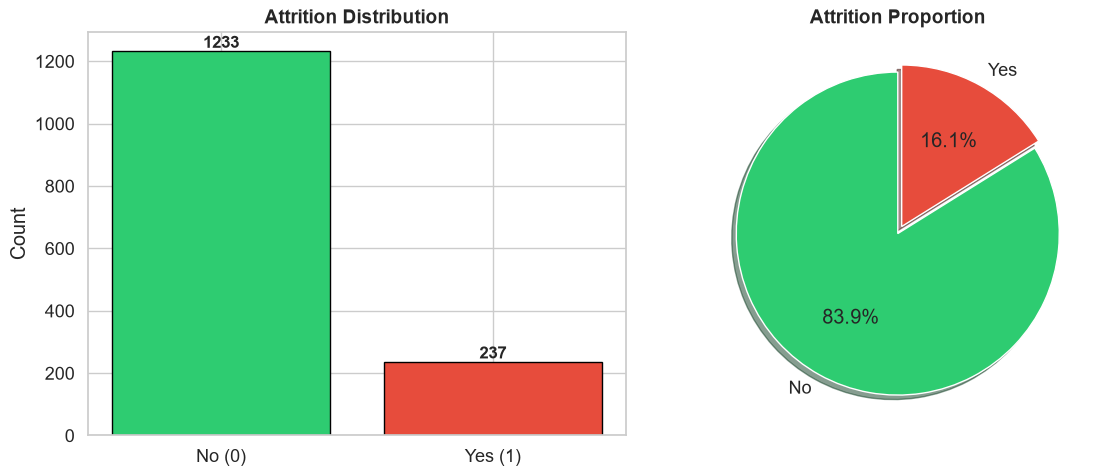

In [5]:
# Encode Target Variable (Attrition: Yes=1, No=0)
print("="*60)
print("TARGET VARIABLE ENCODING")
print("="*60)

print(f"\nOriginal Attrition values: {df['Attrition'].unique()}")
df['Attrition'] = df['Attrition'].map({'Yes': 1, 'No': 0})
print(f"Encoded Attrition values: {df['Attrition'].unique()}")

# Class Balance Visualization
print("\n" + "="*60)
print("CLASS BALANCE")
print("="*60)

attrition_counts = df['Attrition'].value_counts()
print(f"\nNo (0): {attrition_counts[0]} ({attrition_counts[0]/len(df)*100:.1f}%)")
print(f"Yes (1): {attrition_counts[1]} ({attrition_counts[1]/len(df)*100:.1f}%)")

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Bar plot
ax1 = axes[0]
colors = ['#2ecc71', '#e74c3c']
bars = ax1.bar(['No (0)', 'Yes (1)'], attrition_counts.values, color=colors, edgecolor='black')
ax1.set_title('Attrition Distribution', fontsize=14, fontweight='bold')
ax1.set_ylabel('Count')
for bar, count in zip(bars, attrition_counts.values):
    ax1.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 10, 
             f'{count}', ha='center', fontsize=12, fontweight='bold')

# Pie chart
ax2 = axes[1]
ax2.pie(attrition_counts.values, labels=['No', 'Yes'], autopct='%1.1f%%', 
        colors=colors, explode=(0, 0.05), startangle=90, shadow=True)
ax2.set_title('Attrition Proportion', fontsize=14, fontweight='bold')

plt.tight_layout()
plt.show()


## Train-Test Split

In [6]:
# Train-Test Split
import random
import numpy as np
from sklearn.model_selection import train_test_split

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

print("="*60)
print("TRAIN-TEST SPLIT")
print("="*60)

X = df.drop("Attrition", axis=1)
y = df["Attrition"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=SEED, stratify=y
)

print(f"\nTrain shape: {X_train.shape}")
print(f"Test shape: {X_test.shape}")
print("\nTrain target distribution:")
print(f"  - 0 (No): {(y_train==0).sum()}")
print(f"  - 1 (Yes): {(y_train==1).sum()}")
print("\nTest target distribution:")
print(f"  - 0 (No): {(y_test==0).sum()}")
print(f"  - 1 (Yes): {(y_test==1).sum()}")


TRAIN-TEST SPLIT

Train shape: (1176, 30)
Test shape: (294, 30)

Train target distribution:
  - 0 (No): 986
  - 1 (Yes): 190

Test target distribution:
  - 0 (No): 247
  - 1 (Yes): 47


In [7]:
# Encode Categorical Variables on Train Set
print("="*60)
print("ENCODING CATEGORICAL VARIABLES (TRAIN SET)")
print("="*60)

# Binary columns are label-encoded. Nominal labels are retained and then
# smoothed target-encoded inside each model fit.
print("\n--- Binary Variables (Label Encoding) ---")
binary_cols = ['Gender', 'OverTime']
binary_encoders = {}

for col in binary_cols:
    print(f"\n{col}: {X_train[col].unique()}")
    le = LabelEncoder()
    X_train[col] = le.fit_transform(X_train[col].astype(str))
    X_test[col] = le.transform(X_test[col].astype(str))
    binary_encoders[col] = le
    print(f"  -> Encoded: {X_train[col].unique()}")

print("\n--- Nominal Variables (Labels Retained Before Target Encoding) ---")
nominal_cols = ['BusinessTravel', 'Department', 'EducationField', 'JobRole', 'MaritalStatus']
ordinal_cols = [
    'Education', 'EnvironmentSatisfaction', 'JobInvolvement', 'JobLevel',
    'JobSatisfaction', 'PerformanceRating', 'RelationshipSatisfaction',
    'StockOptionLevel', 'TrainingTimesLastYear', 'WorkLifeBalance'
]
ordinal_cols = [col for col in ordinal_cols if col in X_train.columns]

# Nominal labels remain as strings here. The fold-local target encoder converts
# them to numeric values using only the corresponding training fold.
print(f"  -> Nominal labels retained for fold-local target encoding: {nominal_cols}")
print("\n✓ Binary indicators are numeric; nominal variables are encoded inside each model fit")


ENCODING CATEGORICAL VARIABLES (TRAIN SET)

--- Binary Variables (Label Encoding) ---

Gender: <StringArray>
['Female', 'Male']
Length: 2, dtype: str
  -> Encoded: [0 1]

OverTime: <StringArray>
['No', 'Yes']
Length: 2, dtype: str
  -> Encoded: [0 1]

--- Nominal Variables (Labels Retained Before Target Encoding) ---
  -> Nominal labels retained for fold-local target encoding: ['BusinessTravel', 'Department', 'EducationField', 'JobRole', 'MaritalStatus']

✓ Binary indicators are numeric; nominal variables are encoded inside each model fit


OUTLIER DETECTION (Z-SCORE METHOD, TRAIN SET ONLY)
Outliers detected in training partition: 70 rows (5.95%)
Outliers are retained; this cell only reports and visualises them.


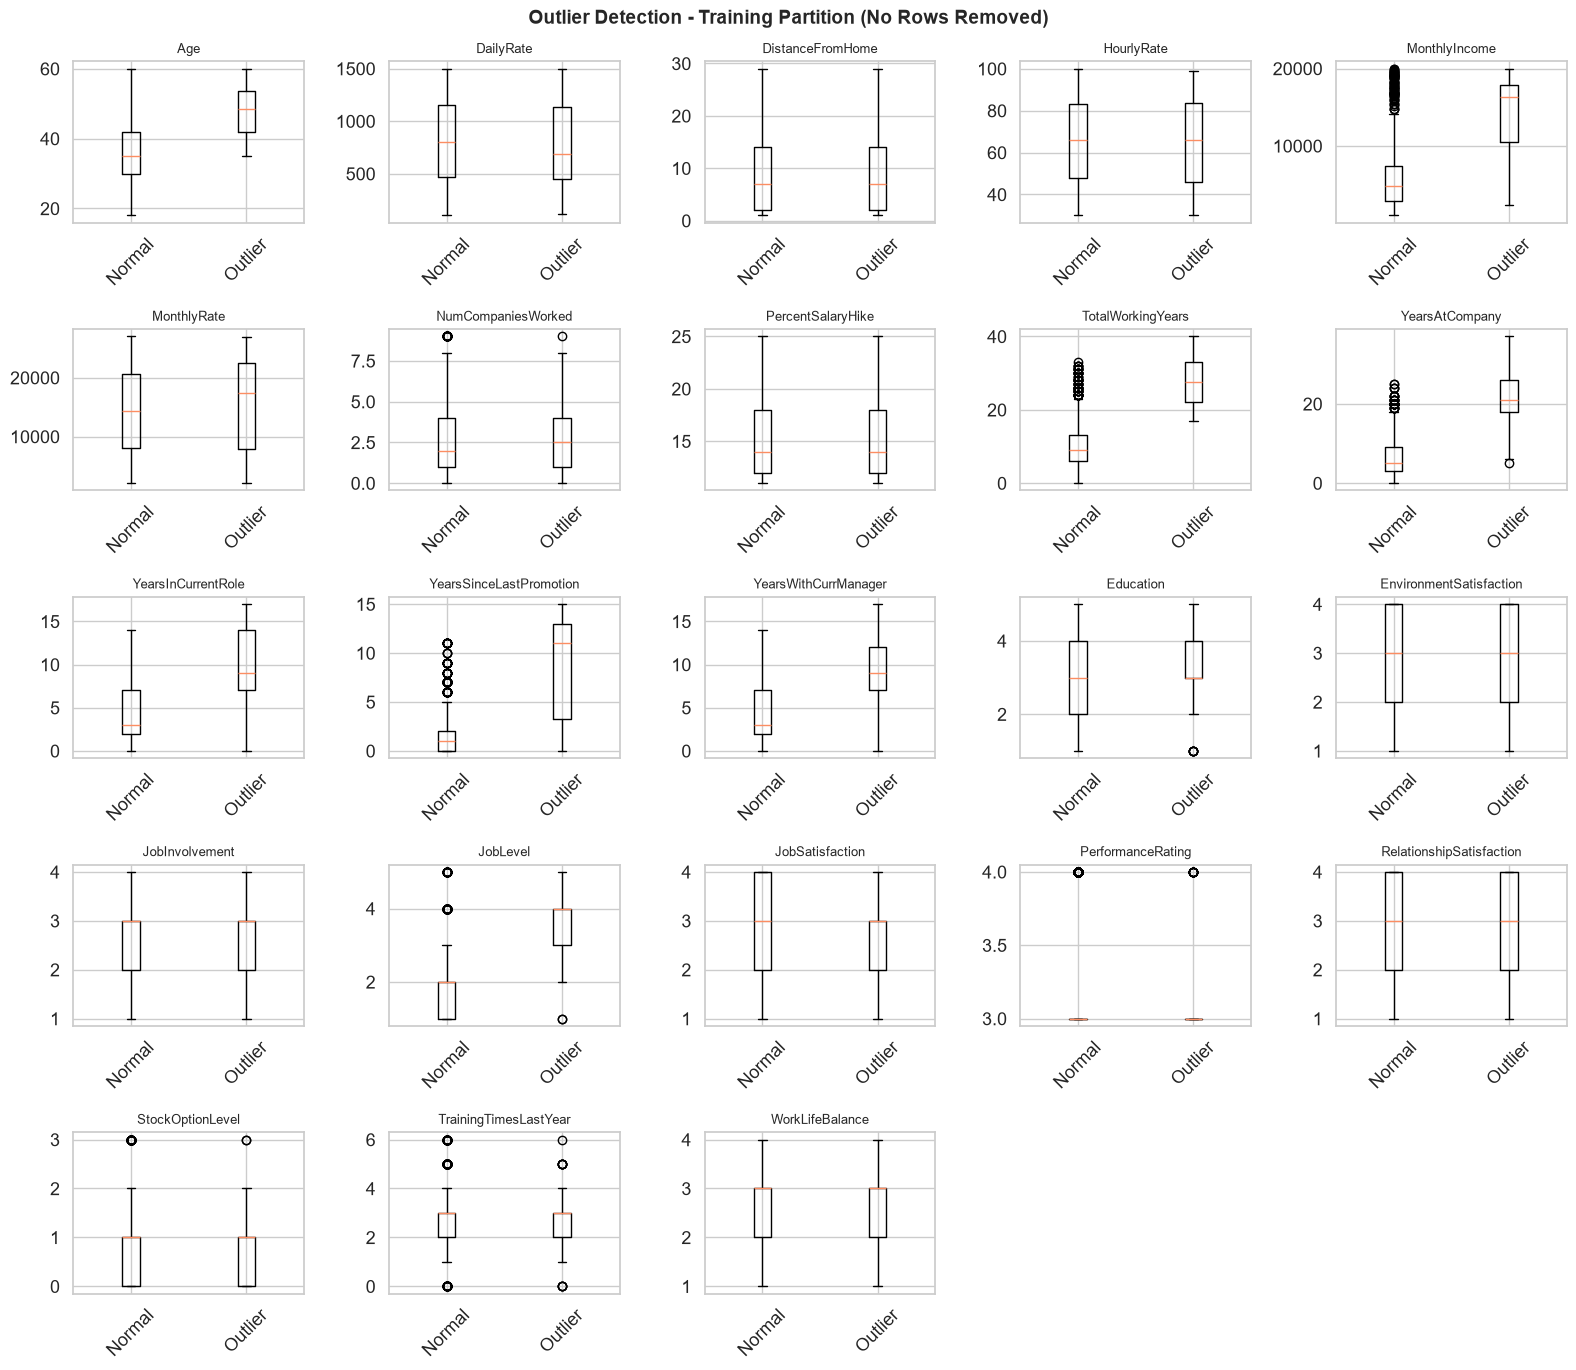

In [8]:
# Outlier Detection using Z-Score Method (Train Set Only) - Visualization Only
from scipy.stats import zscore
import matplotlib.pyplot as plt

print("="*60)
print("OUTLIER DETECTION (Z-SCORE METHOD, TRAIN SET ONLY)")
print("="*60)

numerical_cols = [
    'Age', 'DailyRate', 'DistanceFromHome', 'HourlyRate', 'MonthlyIncome',
    'MonthlyRate', 'NumCompaniesWorked', 'PercentSalaryHike',
    'TotalWorkingYears', 'YearsAtCompany', 'YearsInCurrentRole',
    'YearsSinceLastPromotion', 'YearsWithCurrManager', 'Education',
    'EnvironmentSatisfaction', 'JobInvolvement', 'JobLevel',
    'JobSatisfaction', 'PerformanceRating', 'RelationshipSatisfaction',
    'StockOptionLevel', 'TrainingTimesLastYear', 'WorkLifeBalance'
]
numerical_cols = [col for col in numerical_cols if col in X_train.columns]

z_scores = pd.DataFrame(
    zscore(X_train[numerical_cols], nan_policy='omit'),
    index=X_train.index,
    columns=numerical_cols,
)
outlier_mask = z_scores.abs().gt(3).any(axis=1)
print(f"Outliers detected in training partition: {outlier_mask.sum()} rows ({outlier_mask.mean()*100:.2f}%)")
print("Outliers are retained; this cell only reports and visualises them.")

fig, axes = plt.subplots(5, 5, figsize=(16, 14))
axes = axes.flatten()
for i, col in enumerate(numerical_cols):
    axes[i].boxplot([X_train.loc[~outlier_mask, col], X_train.loc[outlier_mask, col]], tick_labels=['Normal', 'Outlier'])
    axes[i].set_title(col, fontsize=9)
    axes[i].tick_params(axis='x', labelrotation=45)
for axis in axes[len(numerical_cols):]:
    axis.axis('off')
plt.suptitle('Outlier Detection - Training Partition (No Rows Removed)', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()


## Fold-Safe Preprocessing

In [9]:
import numpy as np
import pandas as pd
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.preprocessing import StandardScaler

print("="*60)
print("TARGET ENCODING AND NUMERIC PREPARATION")
print("="*60)

# Preserve the train-only, mixed-type feature matrix for fold-wise pipelines.
# The model pipelines below fit this target encoder inside each CV fold.
X_train_raw_model = X_train.copy()
X_test_raw_model = X_test.copy()

class MEstimateTargetEncoder(BaseEstimator, TransformerMixin):
    """Fold-safe smoothed target encoding for selected nominal columns."""

    def __init__(self, columns=None, m=10):
        self.columns = columns
        self.m = m

    def fit(self, X, y):
        X_df = X.copy() if isinstance(X, pd.DataFrame) else pd.DataFrame(X)
        self.feature_names_in_ = list(X_df.columns)
        self.global_mean_ = float(np.asarray(y).mean())
        self.maps_ = {}
        columns = self.columns if self.columns is not None else self.feature_names_in_
        for col in columns:
            if col not in X_df.columns:
                continue
            temp = pd.DataFrame({"value": X_df[col], "target": np.asarray(y)})
            stats = temp.groupby("value")["target"].agg(["mean", "count"])
            stats["estimate"] = (
                stats["count"] * stats["mean"] + self.m * self.global_mean_
            ) / (stats["count"] + self.m)
            self.maps_[col] = stats["estimate"].to_dict()
        return self

    def transform(self, X):
        X_df = X.copy() if isinstance(X, pd.DataFrame) else pd.DataFrame(
            X, columns=self.feature_names_in_
        )
        X_df = X_df.copy()
        for col, mapping in self.maps_.items():
            if col in X_df.columns:
                X_df[col] = X_df[col].map(mapping).fillna(self.global_mean_)
        return X_df

    def get_feature_names_out(self, input_features=None):
        return np.asarray(input_features if input_features is not None else self.feature_names_in_, dtype=object)


class NonBinaryStandardScaler(BaseEstimator, TransformerMixin):
    """Standardize all available features except designated binary indicators."""

    def __init__(self, binary_columns=None):
        self.binary_columns = binary_columns

    def fit(self, X, y=None):
        X_df = X.copy() if isinstance(X, pd.DataFrame) else pd.DataFrame(X)
        X_df = X_df.astype(float)
        self.feature_names_in_ = list(X_df.columns)
        binary = set(self.binary_columns or [])
        self.scale_columns_ = [
            column for column in self.feature_names_in_ if column not in binary
        ]
        self.scaler_ = StandardScaler()
        if self.scale_columns_:
            self.scaler_.fit(X_df[self.scale_columns_])
        return self

    def transform(self, X):
        X_df = X.copy() if isinstance(X, pd.DataFrame) else pd.DataFrame(
            X, columns=self.feature_names_in_
        )
        transformed = X_df.astype(float)
        if self.scale_columns_:
            transformed.loc[:, self.scale_columns_] = self.scaler_.transform(
                transformed[self.scale_columns_]
            )
        return transformed

    def get_feature_names_out(self, input_features=None):
        return np.asarray(
            input_features if input_features is not None else self.feature_names_in_,
            dtype=object,
        )


def m_estimator_target_encode_fit(X_train_local, y_train_local, col, m=10):
    encoder = MEstimateTargetEncoder(columns=[col], m=m)
    encoder.fit(X_train_local[[col]], y_train_local)
    return encoder.maps_.get(col, {}), encoder.global_mean_


def m_estimator_target_encode_transform(X_local, col, encoding_map, global_mean):
    return X_local[col].map(encoding_map).fillna(global_mean)


nominal_encoders = {}
m_value = 10
print(f"\nApplying M-Estimator Target Encoding (m={m_value}) on the full training partition for export...")
print(f"Global target mean (train): {y_train.mean():.4f}\n")

for col in nominal_cols:
    encoding_map, global_mean = m_estimator_target_encode_fit(X_train, y_train, col, m=m_value)
    nominal_encoders[col] = (encoding_map, global_mean)
    X_train[col] = m_estimator_target_encode_transform(X_train, col, encoding_map, global_mean)
    X_test[col] = m_estimator_target_encode_transform(X_test, col, encoding_map, global_mean)
    print(f"  {col}: {len(encoding_map)} categories encoded")

print("\n✓ Export/feature-ranking matrix prepared from the training partition")


TARGET ENCODING AND NUMERIC PREPARATION

Applying M-Estimator Target Encoding (m=10) on the full training partition for export...
Global target mean (train): 0.1616

  BusinessTravel: 3 categories encoded
  Department: 3 categories encoded
  EducationField: 6 categories encoded
  JobRole: 9 categories encoded
  MaritalStatus: 3 categories encoded

✓ Export/feature-ranking matrix prepared from the training partition


In [10]:
from sklearn.preprocessing import StandardScaler
from imblearn.over_sampling import SMOTE

print("\n" + "="*60)
print("NON-BINARY STANDARD SCALING AND SMOTE")
print("="*60)

# Binary indicators remain 0/1. Every non-binary feature is standardized.
# Ordinary SMOTE is then applied to the numeric training representation.
non_binary_columns = [
    column for column in X_train.columns if column not in binary_cols
]
X_train = X_train.astype(float)
X_test = X_test.astype(float)
scaler = StandardScaler()
X_train.loc[:, non_binary_columns] = scaler.fit_transform(
    X_train[non_binary_columns]
)
X_test.loc[:, non_binary_columns] = scaler.transform(
    X_test[non_binary_columns]
)

smote = SMOTE(random_state=SEED)
X_train_smote, y_train_smote = smote.fit_resample(X_train, y_train)

print("✓ StandardScaler fitted on non-binary training features only")
print("✓ Plain SMOTE applied only to the training partition")
print(f"  Original train shape: {X_train.shape}")
print(f"  SMOTE train shape: {X_train_smote.shape}")
print(f"  Class distribution after SMOTE: {np.bincount(y_train_smote)}")



NON-BINARY STANDARD SCALING AND SMOTE
✓ StandardScaler fitted on non-binary training features only
✓ Plain SMOTE applied only to the training partition
  Original train shape: (1176, 30)
  SMOTE train shape: (1972, 30)
  Class distribution after SMOTE: [986 986]


Test Set Class Distribution:
Class 0: 247 (84.01%)
Class 1: 47 (15.99%)


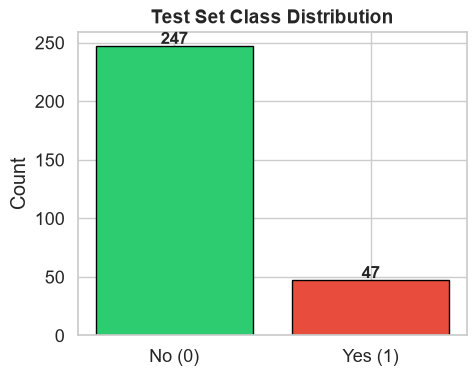

In [11]:
# Display class distribution for the test set
test_counts = y_test.value_counts()
print("Test Set Class Distribution:")
for label, count in test_counts.items():
    print(f"Class {label}: {count} ({count/len(y_test)*100:.2f}%)")

import matplotlib.pyplot as plt
plt.figure(figsize=(5,4))
colors = ['#2ecc71', '#e74c3c']
plt.bar(['No (0)', 'Yes (1)'], [test_counts.get(0,0), test_counts.get(1,0)], color=colors, edgecolor='black')
plt.title('Test Set Class Distribution', fontsize=14, fontweight='bold')
plt.ylabel('Count')
for i, count in enumerate([test_counts.get(0,0), test_counts.get(1,0)]):
    plt.text(i, count + 2, f'{count}', ha='center', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()


## Final Dataset Preprocessing Summary

In [12]:
# Final Dataset Summary
print("="*60)
print("FINAL PREPROCESSING SUMMARY")
print("="*60)

print(f"\nTrain Set (SMOTE applied):")
print(f"  Shape: {X_train_smote.shape}")
print(f"  Class 0 (No): {(y_train_smote==0).sum()}")
print(f"  Class 1 (Yes): {(y_train_smote==1).sum()}")

print(f"\nTest Set (Original, No SMOTE):")
print(f"  Shape: {X_test.shape}")
print(f"  Class 0 (No): {(y_test==0).sum()}")
print(f"  Class 1 (Yes): {(y_test==1).sum()}")

print("\n" + "="*60)
print("COLUMN CATEGORIES")
print("="*60)

# Categorize final columns
binary = ['Gender', 'OverTime']
ordinal = ['Education', 'EnvironmentSatisfaction', 'JobInvolvement', 
           'JobLevel', 'JobSatisfaction', 'PerformanceRating',
           'RelationshipSatisfaction', 'StockOptionLevel', 
           'TrainingTimesLastYear', 'WorkLifeBalance']
numerical = ['Age', 'DailyRate', 'DistanceFromHome', 'HourlyRate', 
             'MonthlyIncome', 'MonthlyRate', 'NumCompaniesWorked',
             'PercentSalaryHike', 'TotalWorkingYears', 'YearsAtCompany',
             'YearsInCurrentRole', 'YearsSinceLastPromotion', 'YearsWithCurrManager']
nominal = ['BusinessTravel', 'Department', 'EducationField', 'JobRole', 'MaritalStatus']

print(f"\nBinary: {len(binary)} columns")
print(f"Ordinal: {len(ordinal)} columns")
print(f"Numerical: {len(numerical)} columns")
print(f"Target Encoded (Nominal): {len(nominal)} columns")
print(f"Total Features: {X_train_smote.shape[1]} columns")

# Preview the numeric matrices produced above.
train_smote_preview = pd.DataFrame(X_train_smote, columns=X_train.columns).copy()
train_smote_preview["Attrition"] = np.asarray(y_train_smote)
test_preview = X_test.copy()
test_preview["Attrition"] = np.asarray(y_test)

pd.set_option('display.max_columns', None)
pd.set_option('display.width', 200)
pd.set_option('display.max_colwidth', None)
print("\nTrain Set (SMOTE) Preview:")
display(train_smote_preview.head())
print("\nTest Set Preview:")
display(test_preview.head())


FINAL PREPROCESSING SUMMARY

Train Set (SMOTE applied):
  Shape: (1972, 30)
  Class 0 (No): 986
  Class 1 (Yes): 986

Test Set (Original, No SMOTE):
  Shape: (294, 30)
  Class 0 (No): 247
  Class 1 (Yes): 47

COLUMN CATEGORIES

Binary: 2 columns
Ordinal: 10 columns
Numerical: 13 columns
Target Encoded (Nominal): 5 columns
Total Features: 30 columns

Train Set (SMOTE) Preview:


,Age,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EnvironmentSatisfaction,Gender,HourlyRate,JobInvolvement,JobLevel,JobRole,JobSatisfaction,MaritalStatus,MonthlyIncome,MonthlyRate,NumCompaniesWorked,OverTime,PercentSalaryHike,PerformanceRating,RelationshipSatisfaction,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager,Attrition
0,1.090194,-0.245733,1.049455,1.385821,-0.899915,1.064209,-0.111947,-0.658710,0.0,-0.908436,1.795282,1.762189,-1.022588,-0.647997,-0.797106,2.026752,0.931289,1.330763,0.0,-0.337129,-0.432065,0.240218,2.613100,2.261482,-0.605389,0.337621,-0.665706,-0.625365,-0.368024,-0.616406,0
1,-1.634828,-0.245733,-0.523449,-0.733727,-0.899915,-1.855332,1.479269,0.260202,1.0,1.694111,0.373564,-0.986265,1.163522,1.153526,-0.622953,-0.864408,0.682742,-1.083704,0.0,-0.337129,-0.432065,0.240218,0.247430,-1.072675,-0.605389,0.337621,-0.830071,-0.905635,-0.056884,-0.897047,0
2,0.981193,-0.245733,-0.992080,1.385821,-0.777610,-1.855332,1.470315,-1.577622,1.0,-0.662913,0.373564,1.762189,-1.022588,0.252765,-0.622953,2.347706,0.167705,0.123529,0.0,-0.880974,-0.432065,1.160403,0.247430,1.492061,0.190962,0.337621,0.813578,1.336527,0.565398,1.348076,0
3,-1.307825,-0.245733,-0.453653,1.385821,0.445433,-1.855332,-0.715715,-0.658710,1.0,-1.252169,0.373564,-0.986265,2.463590,0.252765,-0.622953,-0.956202,1.667056,-0.681293,0.0,-1.152896,-0.432065,0.240218,-0.935405,-0.559727,-1.401740,0.337621,-0.008246,-0.064824,-0.679165,0.506155,0
4,0.654191,1.842426,0.491086,-0.733727,-0.043784,2.037390,-0.715715,1.179114,1.0,0.319180,0.373564,-0.070114,1.163522,0.252765,-0.797106,-0.185956,0.728362,0.123529,1.0,-0.609051,-0.432065,-0.679966,0.247430,-0.175017,0.190962,0.337621,0.156119,0.775986,0.565398,0.786795,0



Test Set Preview:


,Age,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EnvironmentSatisfaction,Gender,HourlyRate,JobInvolvement,JobLevel,JobRole,JobSatisfaction,MaritalStatus,MonthlyIncome,MonthlyRate,NumCompaniesWorked,OverTime,PercentSalaryHike,PerformanceRating,RelationshipSatisfaction,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager,Attrition
1061,-1.416826,-1.716092,0.064832,1.385821,0.445433,-0.882152,-0.111947,1.179114,0.0,0.613808,0.373564,-0.986265,2.463590,-0.647997,-0.622953,-0.969745,-1.013556,-0.681293,0.0,-0.609051,-0.432065,0.240218,0.247430,-1.329148,-0.605389,0.337621,-0.994436,-1.185905,-0.679165,-1.177687,0
891,0.763191,-0.245733,0.780241,-0.733727,-0.899915,-1.855332,-0.111947,-1.577622,0.0,0.319180,1.795282,-0.986265,-0.323570,1.153526,-0.622953,-0.974474,0.777738,-0.681293,0.0,-0.609051,-0.432065,1.160403,0.247430,-0.175017,1.783664,0.337621,0.484849,0.215446,1.498820,0.786795,0
456,-0.653820,-0.245733,-0.289134,1.385821,-0.288393,0.091029,-0.111947,0.260202,1.0,-1.055750,-1.048155,0.846038,-1.022588,1.153526,-0.797106,1.077650,1.516147,2.537997,0.0,1.566330,2.314467,0.240218,0.247430,-0.175017,0.190962,-1.055510,-0.336976,-0.064824,-0.679165,-0.897047,0
922,0.763191,-0.245733,0.984644,-0.733727,-0.655306,-0.882152,-0.111947,0.260202,1.0,1.301274,1.795282,2.678340,-1.022588,-1.548758,-0.797106,2.718533,0.429326,-0.681293,0.0,-0.337129,-0.432065,1.160403,1.430265,1.876772,0.987313,-1.055510,2.950322,1.336527,3.676804,2.470637,0
69,-0.108815,-0.245733,-1.211439,-0.733727,-0.043784,0.091029,-0.715715,1.179114,1.0,0.662913,-1.048155,-0.986265,-0.323570,0.252765,-0.622953,-0.678457,1.027398,-1.083704,1.0,0.478639,-0.432065,-1.600151,0.247430,-1.200911,-2.198092,-1.055510,-0.994436,-1.185905,-0.679165,-1.177687,1


## Feature Selection

In [13]:
import numpy as np
from skrebate import ReliefF, MultiSURF

print("="*60)
print("FEATURE SELECTION - ReliefF AND MultiSURF")
print("="*60)

# This full-training ranking is used only to fit the final model after the
# feature count has been selected. Fold-local rankings are calculated later
# during cross-validation so that validation labels cannot influence ranking.
feature_names = X_train.columns.tolist()
X_train_np = np.asarray(X_train, dtype=float)
y_train_np = np.asarray(y_train)
ranking_categorical_indices = [
    feature_names.index(column) for column in binary_cols if column in feature_names
]

print(f"\nFeature matrix for final full-training ranking: {X_train.shape}")
print(f"Target distribution: No={sum(y_train==0)}, Yes={sum(y_train==1)}")
print("Only binary indicators are categorical in ReliefF/MultiSURF; encoded ordinal features retain their order.")


FEATURE SELECTION - ReliefF AND MultiSURF

Feature matrix for final full-training ranking: (1176, 30)
Target distribution: No=986, Yes=190
Only binary indicators are categorical in ReliefF/MultiSURF; encoded ordinal features retain their order.


In [14]:
print("ReliefF Feature Ranking")
print("-"*60)

relieff = ReliefF(n_features_to_select=X_train_np.shape[1], n_neighbors=100, categorical_features=ranking_categorical_indices, n_jobs=-1)
relieff.fit(X_train_np, y_train_np)
relieff_scores_dict = dict(zip(feature_names, relieff.feature_importances_))
relieff_sorted = sorted(relieff_scores_dict.items(), key=lambda x: x[1], reverse=True)

print("\nAll Features Ranked by ReliefF Score:")
for i, (feat, score) in enumerate(relieff_sorted, 1):
    print(f"  {i:2d}. {feat}: {score:.4f}")


ReliefF Feature Ranking
------------------------------------------------------------

All Features Ranked by ReliefF Score:
   1. OverTime: 0.1752
   2. Gender: 0.1672
   3. MaritalStatus: 0.1404
   4. JobRole: 0.1308
   5. Department: 0.1124
   6. Age: 0.0807
   7. TotalWorkingYears: 0.0791
   8. StockOptionLevel: 0.0759
   9. WorkLifeBalance: 0.0689
  10. EnvironmentSatisfaction: 0.0674
  11. JobLevel: 0.0664
  12. YearsAtCompany: 0.0577
  13. MonthlyIncome: 0.0529
  14. BusinessTravel: 0.0509
  15. NumCompaniesWorked: 0.0506
  16. JobSatisfaction: 0.0500
  17. YearsInCurrentRole: 0.0498
  18. YearsWithCurrManager: 0.0480
  19. RelationshipSatisfaction: 0.0463
  20. DistanceFromHome: 0.0458
  21. JobInvolvement: 0.0441
  22. EducationField: 0.0435
  23. PercentSalaryHike: 0.0404
  24. PerformanceRating: 0.0382
  25. DailyRate: 0.0344
  26. HourlyRate: 0.0300
  27. MonthlyRate: 0.0263
  28. Education: 0.0214
  29. TrainingTimesLastYear: 0.0208
  30. YearsSinceLastPromotion: 0.0200


In [15]:
print("MultiSURF Feature Ranking")
print("-"*60)

multisurf = MultiSURF(n_features_to_select=X_train_np.shape[1], categorical_features=ranking_categorical_indices, n_jobs=-1)
multisurf.fit(X_train_np, y_train_np)
multisurf_scores_dict = dict(zip(feature_names, multisurf.feature_importances_))
multisurf_sorted = sorted(multisurf_scores_dict.items(), key=lambda x: x[1], reverse=True)

print("\nAll Features Ranked by MultiSURF Score:")
for i, (feat, score) in enumerate(multisurf_sorted, 1):
    print(f"  {i:2d}. {feat}: {score:.4f}")


MultiSURF Feature Ranking
------------------------------------------------------------

All Features Ranked by MultiSURF Score:
   1. JobRole: 0.0753
   2. MaritalStatus: 0.0748
   3. WorkLifeBalance: 0.0545
   4. Department: 0.0461
   5. JobInvolvement: 0.0423
   6. Age: 0.0354
   7. EducationField: 0.0318
   8. EnvironmentSatisfaction: 0.0315
   9. BusinessTravel: 0.0235
  10. TotalWorkingYears: 0.0226
  11. DistanceFromHome: 0.0219
  12. JobSatisfaction: 0.0197
  13. NumCompaniesWorked: 0.0177
  14. DailyRate: 0.0145
  15. StockOptionLevel: 0.0144
  16. YearsAtCompany: 0.0123
  17. RelationshipSatisfaction: 0.0077
  18. HourlyRate: 0.0050
  19. TrainingTimesLastYear: 0.0021
  20. Gender: 0.0013
  21. JobLevel: 0.0005
  22. PercentSalaryHike: 0.0004
  23. YearsInCurrentRole: 0.0003
  24. YearsWithCurrManager: -0.0006
  25. PerformanceRating: -0.0015
  26. MonthlyRate: -0.0046
  27. Education: -0.0099
  28. YearsSinceLastPromotion: -0.0111
  29. MonthlyIncome: -0.0126
  30. OverTime: 

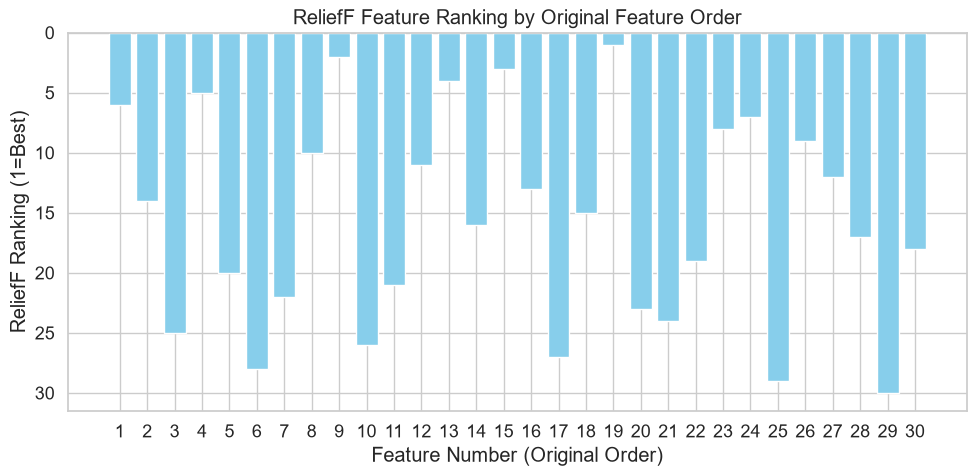

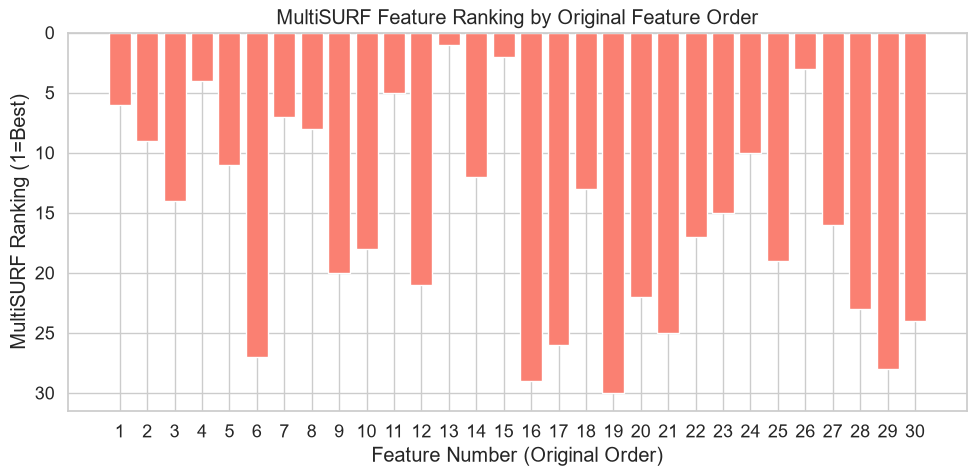

In [16]:
# Visualization: Feature Ranking (Y=Ranking, X=Feature Number, Original Order)
import matplotlib.pyplot as plt
import numpy as np

# Get feature names in original order
feature_numbers = np.arange(1, len(feature_names)+1)

# ReliefF: get ranking for each feature in original order
relieff_ranking = [
    [feat for feat, _ in relieff_sorted].index(f) + 1 for f in feature_names
]
plt.figure(figsize=(10, 5))
plt.bar(feature_numbers, relieff_ranking, color='skyblue')
plt.ylabel('ReliefF Ranking (1=Best)')
plt.xlabel('Feature Number (Original Order)')
plt.title('ReliefF Feature Ranking by Original Feature Order')
plt.xticks(feature_numbers)
plt.gca().invert_yaxis()  # 1 is best, so invert
plt.tight_layout()
plt.show()

# MultiSURF: get ranking for each feature in original order
multisurf_ranking = [
    [feat for feat, _ in multisurf_sorted].index(f) + 1 for f in feature_names
]
plt.figure(figsize=(10, 5))
plt.bar(feature_numbers, multisurf_ranking, color='salmon')
plt.ylabel('MultiSURF Ranking (1=Best)')
plt.xlabel('Feature Number (Original Order)')
plt.title('MultiSURF Feature Ranking by Original Feature Order')
plt.xticks(feature_numbers)
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

  


## Model Development and Cross-Validation

In [17]:
from sklearn.base import clone
from sklearn.ensemble import RandomForestClassifier, VotingClassifier, GradientBoostingClassifier
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_val_score
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from xgboost import XGBClassifier
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE

print("="*60)
print("F1-OPTIMISED MODEL TUNING AND VOTING EVALUATION - IBM")
print("="*60)

scoring_metric = "f1"
cv_splitter = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

rf_param_grid = {
    "n_estimators": [100, 200],
    "max_depth": [None, 5, 10],
    "min_samples_split": [2, 5],
    "min_samples_leaf": [1, 2],
}
xgb_param_grid = {
    "n_estimators": [100, 200],
    "max_depth": [3, 5, 7],
    "learning_rate": [0.1, 0.3],
    "subsample": [0.8, 1.0],
}
svm_param_grid = {
    "C": [0.1, 1, 10],
    "kernel": ["rbf"],
    "gamma": ["scale", "auto"],
}
dt_param_grid = {
    "max_depth": [None, 5, 10],
    "min_samples_split": [2, 5],
    "min_samples_leaf": [1, 2],
}
gb_param_grid = {
    "n_estimators": [100, 200],
    "learning_rate": [0.05, 0.1],
    "max_depth": [3, 5],
    "subsample": [0.8, 1.0],
}

def prefix_grid(grid, prefix="clf"):
    return {f"{prefix}__{k}": v for k, v in grid.items()}

def build_model_pipeline(estimator, use_smote=True, smote_seed=None):
    steps = [
        ("target_encode", MEstimateTargetEncoder(columns=nominal_cols, m=m_value)),
        ("scale_non_binary", NonBinaryStandardScaler(binary_columns=binary_cols)),
    ]
    if use_smote:
        steps.append(("smote", SMOTE(random_state=SEED if smote_seed is None else smote_seed)))
    steps.append(("clf", estimator))
    return ImbPipeline(steps)

def tune_model(estimator, grid):
    pipeline = build_model_pipeline(estimator)
    search = GridSearchCV(
        pipeline,
        prefix_grid(grid),
        cv=cv_splitter,
        scoring=scoring_metric,
        n_jobs=-1,
        refit=True,
    )
    search.fit(X_train_raw_model, y_train)
    print(f"{estimator.__class__.__name__} best CV F1: {search.best_score_:.4f}")
    print(f"  best parameters: {search.best_params_}")
    return search

gs_rf = tune_model(RandomForestClassifier(random_state=SEED), rf_param_grid)
gs_xgb = tune_model(XGBClassifier(random_state=SEED, eval_metric="logloss"), xgb_param_grid)
gs_svm = tune_model(SVC(probability=True, random_state=SEED), svm_param_grid)
gs_dt = tune_model(DecisionTreeClassifier(random_state=SEED), dt_param_grid)
gs_gb = tune_model(GradientBoostingClassifier(random_state=SEED), gb_param_grid)

# Use the tuned classifier settings as the voting components. Preprocessing and
# SMOTE are applied by build_model_pipeline inside each CV fold.
rf = clone(gs_rf.best_estimator_.named_steps["clf"])
xgb = clone(gs_xgb.best_estimator_.named_steps["clf"])
svm = clone(gs_svm.best_estimator_.named_steps["clf"])
dt = clone(gs_dt.best_estimator_.named_steps["clf"])
gb = clone(gs_gb.best_estimator_.named_steps["clf"])

voting_clf = VotingClassifier(
    estimators=[("rf", clone(rf)), ("gb", clone(gb)), ("svm", clone(svm)), ("dt", clone(dt))],
    voting="soft",
)

# Every voting combination is evaluated and optimized independently. The
# additional combinations are shown in tables but are not added to the main
# top-N figure.
voting_models = {
    "General Voting": voting_clf,
    "Hard GB + XGBoost + SVM": VotingClassifier(
        estimators=[("gb", clone(gb)), ("xgb", clone(xgb)), ("svm", clone(svm))], voting="hard"
    ),
    "Hard RF + GB + XGBoost": VotingClassifier(
        estimators=[("rf", clone(rf)), ("gb", clone(gb)), ("xgb", clone(xgb))], voting="hard"
    ),
    "Hard RF + XGBoost + SVM": VotingClassifier(
        estimators=[("rf", clone(rf)), ("xgb", clone(xgb)), ("svm", clone(svm))], voting="hard"
    ),
    "Hard All Five": VotingClassifier(
        estimators=[("rf", clone(rf)), ("gb", clone(gb)), ("xgb", clone(xgb)), ("svm", clone(svm)), ("dt", clone(dt))], voting="hard"
    ),
    "Voting GB + XGBoost (equal weights)": VotingClassifier(
        estimators=[("gb", clone(gb)), ("xgb", clone(xgb))],
        voting="soft",
    ),
    "Voting RF + XGBoost": VotingClassifier(
        estimators=[("rf", clone(rf)), ("xgb", clone(xgb))],
        voting="soft",
    ),
    "Voting GB + SVM": VotingClassifier(
        estimators=[("gb", clone(gb)), ("svm", clone(svm))],
        voting="soft",
    ),
    "Voting GB + XGBoost + SVM": VotingClassifier(
        estimators=[("gb", clone(gb)), ("xgb", clone(xgb)), ("svm", clone(svm))],
        voting="soft",
    ),
    "Voting RF + GB + XGBoost": VotingClassifier(
        estimators=[("rf", clone(rf)), ("gb", clone(gb)), ("xgb", clone(xgb))],
        voting="soft",
    ),
    "Voting All Five": VotingClassifier(
        estimators=[("rf", clone(rf)), ("gb", clone(gb)), ("xgb", clone(xgb)), ("svm", clone(svm)), ("dt", clone(dt))],
        voting="soft",
    ),
}

cv_models = {
    "Random Forest": rf,
    "XGBoost": xgb,
    "SVM": svm,
    "Decision Tree": dt,
    "Gradient Boosting": gb,
}
cv_models.update(voting_models)

cv_results = []
for name, estimator in cv_models.items():
    scores = cross_val_score(
        build_model_pipeline(clone(estimator)),
        X_train_raw_model,
        y_train,
        cv=cv_splitter,
        scoring="f1",
        n_jobs=-1,
    )
    cv_results.append({"Model": name, "Mean CV F1": scores.mean(), "Std CV F1": scores.std()})
    print(f"{name}: mean CV F1={scores.mean():.4f}, std={scores.std():.4f}")

cv_results = pd.DataFrame(cv_results)
display(cv_results.sort_values("Mean CV F1", ascending=False).round(4))

def positive_scores(fitted_model, X):

    """Return probability, decision score, or hard positive-vote fraction."""
    classifier = fitted_model.named_steps["clf"]
    if isinstance(classifier, VotingClassifier) and classifier.voting == "hard":
        prepared = fitted_model.named_steps["target_encode"].transform(X)
        prepared = fitted_model.named_steps["scale_non_binary"].transform(prepared)
        return classifier.transform(prepared).mean(axis=1)
    try:
        return fitted_model.predict_proba(X)[:, 1]
    except (AttributeError, NotImplementedError):
        if hasattr(fitted_model, "decision_function"):
            return fitted_model.decision_function(X)
        return None

def run_to_run_variance(estimator, X_features, y_target, model_name, seeds=(SEED, SEED + 1, SEED + 2)):
    """Evaluate CV-F1 stability across seeds for a fixed feature subset."""
    rows = []
    for run_seed in seeds:
        run_estimator = clone(estimator)
        seed_params = {
            name: run_seed
            for name in run_estimator.get_params(deep=True)
            if name.endswith("random_state")
        }
        if seed_params:
            run_estimator.set_params(**seed_params)
        run_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=run_seed)
        run_scores = cross_val_score(
            build_model_pipeline(run_estimator, smote_seed=run_seed),
            X_features,
            y_target,
            cv=run_cv,
            scoring="f1",
            n_jobs=-1,
        )
        rows.append({"Model": model_name, "Seed": run_seed, "Mean CV F1": run_scores.mean(), "Fold SD": run_scores.std()})
    return pd.DataFrame(rows)


F1-OPTIMISED MODEL TUNING AND VOTING EVALUATION - IBM
RandomForestClassifier best CV F1: 0.5365
  best parameters: {'clf__max_depth': 5, 'clf__min_samples_leaf': 2, 'clf__min_samples_split': 5, 'clf__n_estimators': 100}
XGBClassifier best CV F1: 0.5642
  best parameters: {'clf__learning_rate': 0.1, 'clf__max_depth': 3, 'clf__n_estimators': 200, 'clf__subsample': 0.8}
SVC best CV F1: 0.5116
  best parameters: {'clf__C': 1, 'clf__gamma': 'scale', 'clf__kernel': 'rbf'}
DecisionTreeClassifier best CV F1: 0.4280
  best parameters: {'clf__max_depth': 5, 'clf__min_samples_leaf': 1, 'clf__min_samples_split': 2}
GradientBoostingClassifier best CV F1: 0.5356
  best parameters: {'clf__learning_rate': 0.1, 'clf__max_depth': 3, 'clf__n_estimators': 200, 'clf__subsample': 1.0}
Random Forest: mean CV F1=0.5365, std=0.0994
XGBoost: mean CV F1=0.5642, std=0.0703
SVM: mean CV F1=0.5116, std=0.0574
Decision Tree: mean CV F1=0.4280, std=0.0190
Gradient Boosting: mean CV F1=0.5356, std=0.0613
General Votin

,Model,Mean CV F1,Std CV F1
8,Hard RF + XGBoost + SVM,0.5756,0.0744
1,XGBoost,0.5642,0.0703
11,Voting RF + XGBoost,0.5609,0.0705
7,Hard RF + GB + XGBoost,0.5592,0.0634
15,Voting All Five,0.5590,0.0745
14,Voting RF + GB + XGBoost,0.5561,0.0618
9,Hard All Five,0.5552,0.0645
10,Voting GB + XGBoost (equal weights),0.5543,0.0664
6,Hard GB + XGBoost + SVM,0.5542,0.0734
13,Voting GB + XGBoost + SVM,0.5404,0.0529


In [18]:
import numpy as np
import pandas as pd
from joblib import Parallel, delayed
from sklearn.base import clone
from sklearn.metrics import f1_score

print("="*60)
print("FOLD-LOCAL TOP-N FEATURE CURVES USING F1 - IBM")
print("="*60)

max_n = len(feature_names)
cv_folds = cv_splitter
scoring = "f1"

base_model_templates = {
    "Random Forest": rf,
    "XGBoost": xgb,
    "SVM": svm,
    "Decision Tree": dt,
    "Gradient Boosting": gb,
}
model_templates = {**base_model_templates, **voting_models}


def make_selector(selector_name, feature_count, categorical_indices):
    common = {
        "n_features_to_select": feature_count,
        "categorical_features": categorical_indices,
        "n_jobs": 1,
    }
    if selector_name == "ReliefF":
        return ReliefF(n_neighbors=100, **common)
    return MultiSURF(**common)


def prepare_fold_rankings():
    cache = []
    for fold_number, (fit_positions, validation_positions) in enumerate(
        cv_folds.split(X_train_raw_model, y_train), start=1
    ):
        X_fit = X_train_raw_model.iloc[fit_positions].copy()
        y_fit = y_train.iloc[fit_positions]

        fold_encoder = MEstimateTargetEncoder(columns=nominal_cols, m=m_value)
        X_fit_encoded = fold_encoder.fit_transform(X_fit, y_fit)
        fold_scaler = NonBinaryStandardScaler(binary_columns=binary_cols)
        X_fit_prepared = fold_scaler.fit_transform(X_fit_encoded)

        fold_features = list(X_fit.columns)
        categorical_indices = [
            fold_features.index(column)
            for column in binary_cols
            if column in fold_features
        ]
        fold_rankings = {}
        for selector_name in ("ReliefF", "MultiSURF"):
            selector = make_selector(selector_name, len(fold_features), categorical_indices)
            selector.fit(np.asarray(X_fit_prepared, dtype=float), np.asarray(y_fit))
            order = np.argsort(selector.feature_importances_)[::-1]
            fold_rankings[selector_name] = [fold_features[index] for index in order]

        cache.append({
            "fold": fold_number,
            "fit_positions": fit_positions,
            "validation_positions": validation_positions,
            "rankings": fold_rankings,
        })
        print(f"Prepared fold-local ReliefF and MultiSURF rankings for fold {fold_number}/5")
    return cache


fold_local_ranking_cache = prepare_fold_rankings()


def score_one_fold(estimator, selected_features, fit_positions, validation_positions):
    fitted = build_model_pipeline(clone(estimator))
    fitted.fit(
        X_train_raw_model.iloc[fit_positions].loc[:, selected_features],
        y_train.iloc[fit_positions],
    )
    predictions = fitted.predict(
        X_train_raw_model.iloc[validation_positions].loc[:, selected_features]
    )
    return f1_score(y_train.iloc[validation_positions], predictions, zero_division=0)


def evaluate_top_n(selector_name, n, estimator):
    fold_scores = Parallel(n_jobs=-1)(
        delayed(score_one_fold)(
            estimator,
            fold["rankings"][selector_name][:n],
            fold["fit_positions"],
            fold["validation_positions"],
        )
        for fold in fold_local_ranking_cache
    )
    return float(np.mean(fold_scores))


scores = {
    "relief": {name: [] for name in model_templates},
    "multi": {name: [] for name in model_templates},
}

for n in range(1, max_n + 1):
    print(f"Evaluating feature count {n}/{max_n}")
    for name, estimator in model_templates.items():
        scores["relief"][name].append(evaluate_top_n("ReliefF", n, estimator))
        scores["multi"][name].append(evaluate_top_n("MultiSURF", n, estimator))

# Compatibility aliases used by the reporting and plotting cells.
rf_acc_relief = scores["relief"]["Random Forest"]
xgb_acc_relief = scores["relief"]["XGBoost"]
svm_acc_relief = scores["relief"]["SVM"]
dt_acc_relief = scores["relief"]["Decision Tree"]
gb_acc_relief = scores["relief"]["Gradient Boosting"]
voting_clf_acc_relief = scores["relief"]["General Voting"]
rf_acc_multi = scores["multi"]["Random Forest"]
xgb_acc_multi = scores["multi"]["XGBoost"]
svm_acc_multi = scores["multi"]["SVM"]
dt_acc_multi = scores["multi"]["Decision Tree"]
gb_acc_multi = scores["multi"]["Gradient Boosting"]
voting_clf_acc_multi = scores["multi"]["General Voting"]


def first_argmax(values):
    maximum = max(values)
    return next(i + 1 for i, value in enumerate(values) if value == maximum)


best_feature_counts = {
    selector_name: {
        model_name: first_argmax(model_scores)
        for model_name, model_scores in selector_scores.items()
    }
    for selector_name, selector_scores in [
        ("ReliefF", scores["relief"]),
        ("MultiSURF", scores["multi"]),
    ]
}

best_cv_f1 = {
    selector_name: {
        model_name: max(model_scores)
        for model_name, model_scores in selector_scores.items()
    }
    for selector_name, selector_scores in [
        ("ReliefF", scores["relief"]),
        ("MultiSURF", scores["multi"]),
    ]
}

best_rf_relief = best_feature_counts["ReliefF"]["Random Forest"]
best_xgb_relief = best_feature_counts["ReliefF"]["XGBoost"]
best_svm_relief = best_feature_counts["ReliefF"]["SVM"]
best_dt_relief = best_feature_counts["ReliefF"]["Decision Tree"]
best_gb_relief = best_feature_counts["ReliefF"]["Gradient Boosting"]
best_voting_relief = best_feature_counts["ReliefF"]["General Voting"]
best_rf_multi = best_feature_counts["MultiSURF"]["Random Forest"]
best_xgb_multi = best_feature_counts["MultiSURF"]["XGBoost"]
best_svm_multi = best_feature_counts["MultiSURF"]["SVM"]
best_dt_multi = best_feature_counts["MultiSURF"]["Decision Tree"]
best_gb_multi = best_feature_counts["MultiSURF"]["Gradient Boosting"]
best_voting_multi = best_feature_counts["MultiSURF"]["General Voting"]

voting_feature_rows = []
for selector_name, score_key in (("ReliefF", "relief"), ("MultiSURF", "multi")):
    for model_name in voting_models:
        n = best_feature_counts[selector_name][model_name]
        voting_feature_rows.append({
            "Feature Selection": selector_name,
            "Model": model_name,
            "Optimal Features": n,
            "Best CV F1": best_cv_f1[selector_name][model_name],
        })
voting_feature_summary = pd.DataFrame(voting_feature_rows)
print("Each classifier uses its own feature count selected with fold-local ranking:")
display(voting_feature_summary.sort_values(
    ["Feature Selection", "Best CV F1"], ascending=[True, False]
).round(4))
print("Feature-count rule: choose the smallest N attaining the maximum mean CV F1.")


# Select before evaluating any holdout predictions. Original full-feature
# CV scores already exist from the model-development cell.
from pathlib import Path
import json

results_dir = Path("ibm_reviewed_v1_results")
results_dir.mkdir(exist_ok=True)
all_features_cv = cv_results.set_index("Model")["Mean CV F1"].to_dict()
selection_rows = [
    {"Feature Selection": "All features", "Model": name,
      "Features": X_train_raw_model.shape[1], "CV F1": all_features_cv[name]}
    for name in model_templates
]
for selector_name, score_key in (("ReliefF", "relief"), ("MultiSURF", "multi")):
    for name in model_templates:
        n = best_feature_counts[selector_name][name]
        selection_rows.append({
            "Feature Selection": selector_name, "Model": name,
            "Features": n, "CV F1": scores[score_key][name][n - 1],
        })
training_cv_candidates = pd.DataFrame(selection_rows).sort_values(
    ["CV F1", "Features", "Feature Selection", "Model"],
    ascending=[False, True, True, True], kind="stable",
).reset_index(drop=True)
selected_configuration = training_cv_candidates.iloc[0].copy()
selected_key = (selected_configuration["Feature Selection"], selected_configuration["Model"])
training_cv_candidates.to_csv(results_dir / "training_cv_candidates.csv", index=False)
curve_rows = [
    {"Feature Selection": selector, "Model": name, "Features": n, "CV F1": value}
    for selector, key in (("ReliefF", "relief"), ("MultiSURF", "multi"))
    for name, values in scores[key].items()
    for n, value in enumerate(values, 1)
]
pd.DataFrame(curve_rows).to_csv(results_dir / "feature_count_curves.csv", index=False)
selection_details = {
    "choice": selected_configuration.to_dict(),
    "rule": "Maximum unrounded mean training CV F1, then fewer features, selector/model alphabetical order",
    "seed": SEED, "folds": cv_splitter.n_splits,
    "final_parameters": {name: estimator.get_params(deep=True)
                         for name, estimator in base_model_templates.items()},
    "search_grids": {"RF": rf_param_grid, "XGBoost": xgb_param_grid,
                     "SVM": svm_param_grid, "DT": dt_param_grid, "GB": gb_param_grid},
    "training_indices": X_train_raw_model.index.tolist(),
    "test_indices": X_test_raw_model.index.tolist(),
}
(results_dir / "training_selection.json").write_text(
    json.dumps(selection_details, indent=2, default=str), encoding="utf-8")
print("Configuration selected by training CV:")
display(selected_configuration.to_frame("Selected configuration"))


FOLD-LOCAL TOP-N FEATURE CURVES USING F1 - IBM
Prepared fold-local ReliefF and MultiSURF rankings for fold 1/5
Prepared fold-local ReliefF and MultiSURF rankings for fold 2/5
Prepared fold-local ReliefF and MultiSURF rankings for fold 3/5
Prepared fold-local ReliefF and MultiSURF rankings for fold 4/5
Prepared fold-local ReliefF and MultiSURF rankings for fold 5/5
Evaluating feature count 1/30
Evaluating feature count 2/30
Evaluating feature count 3/30
Evaluating feature count 4/30
Evaluating feature count 5/30
Evaluating feature count 6/30
Evaluating feature count 7/30
Evaluating feature count 8/30
Evaluating feature count 9/30
Evaluating feature count 10/30
Evaluating feature count 11/30
Evaluating feature count 12/30
Evaluating feature count 13/30
Evaluating feature count 14/30
Evaluating feature count 15/30
Evaluating feature count 16/30
Evaluating feature count 17/30
Evaluating feature count 18/30
Evaluating feature count 19/30
Evaluating feature count 20/30
Evaluating feature cou

,Feature Selection,Model,Optimal Features,Best CV F1
14,MultiSURF,Hard RF + XGBoost + SVM,30,0.5786
13,MultiSURF,Hard RF + GB + XGBoost,30,0.5574
21,MultiSURF,Voting All Five,30,0.5570
15,MultiSURF,Hard All Five,30,0.5553
20,MultiSURF,Voting RF + GB + XGBoost,30,0.5526
17,MultiSURF,Voting RF + XGBoost,30,0.5518
16,MultiSURF,Voting GB + XGBoost (equal weights),30,0.5497
12,MultiSURF,Hard GB + XGBoost + SVM,30,0.5494
19,MultiSURF,Voting GB + XGBoost + SVM,30,0.5404
11,MultiSURF,General Voting,30,0.5313


Feature-count rule: choose the smallest N attaining the maximum mean CV F1.
Configuration selected by training CV:


,Selected configuration
Feature Selection,MultiSURF
Model,Hard RF + XGBoost + SVM
Features,30
CV F1,0.578561


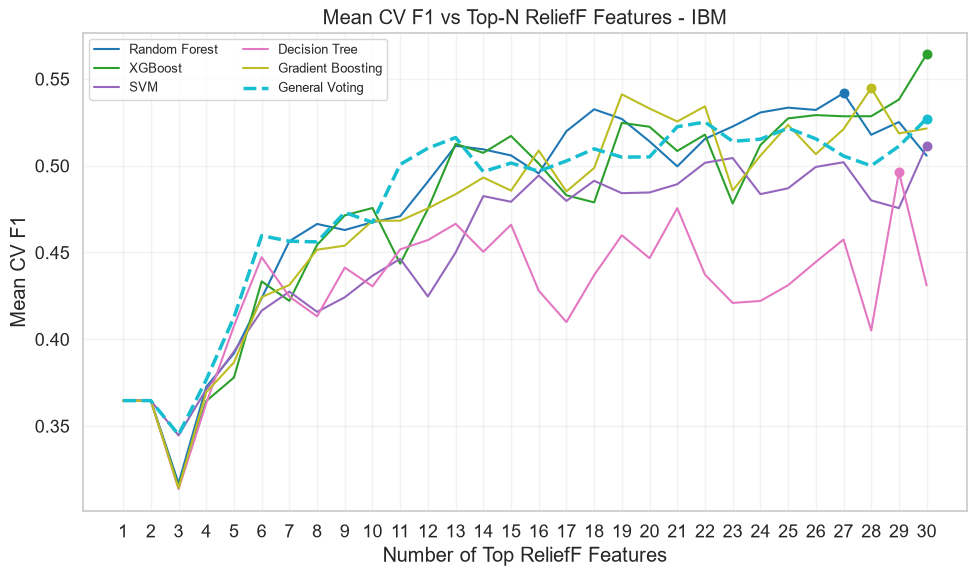

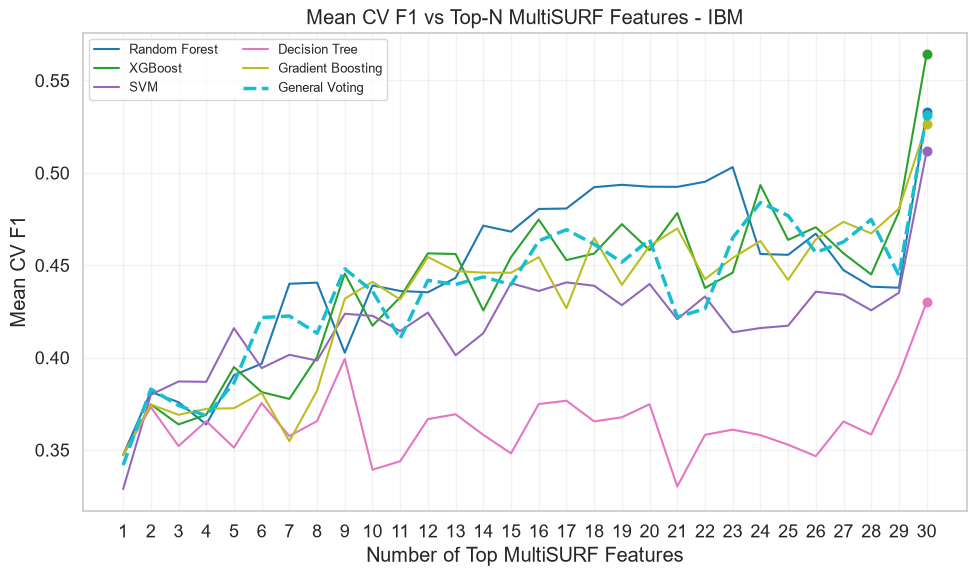

In [19]:
import numpy as np
import matplotlib.pyplot as plt

# Show Top-N behaviour for the five individual classifiers and General Voting.
# The holdout-winning voting architecture is compared separately after the
# holdout evaluation.
n_values = np.arange(1, max_n + 1)
comparison_model_names = list(base_model_templates.keys()) + ["General Voting"]
missing_curve_models = [
    name for name in comparison_model_names
    if name not in scores["relief"] or name not in scores["multi"]
]
if missing_curve_models:
    raise KeyError(f"Missing Top-N CV curves for: {missing_curve_models}")


def plot_top_n_curves(score_key, selector_name):
    plt.figure(figsize=(10, 6))
    colours = plt.cm.tab10(np.linspace(0, 1, len(comparison_model_names)))
    for colour, model_name in zip(colours, comparison_model_names):
        curve = np.asarray(scores[score_key][model_name], dtype=float)
        optimal_n = best_feature_counts[selector_name][model_name]
        is_voting = model_name == "General Voting"
        plt.plot(
            n_values,
            curve,
            label=model_name,
            color=colour,
            linewidth=2.5 if is_voting else 1.5,
            linestyle="--" if is_voting else "-",
        )
        plt.scatter(optimal_n, curve[optimal_n - 1], color=colour, s=38, zorder=3)
    plt.xlabel(f"Number of Top {selector_name} Features")
    plt.ylabel("Mean CV F1")
    plt.title(f"Mean CV F1 vs Top-N {selector_name} Features - IBM")
    plt.xticks(n_values)
    plt.legend(ncol=2, fontsize=9)
    plt.grid(alpha=0.25)
    plt.tight_layout()
    plt.show()


plot_top_n_curves("relief", "ReliefF")
plot_top_n_curves("multi", "MultiSURF")


### Feature-count optimisation for the final voting configuration

This plot compares ReliefF and MultiSURF using the same final IBM voting architecture. The selected point is the smallest feature count attaining the maximum mean five-fold CV F1.

## Holdout Evaluation

The CV-selected row is marked. Other holdout rows are descriptive comparisons on a split that was previously inspected. Average Precision (AP) summarises the precision-recall curve. Hard-voting AUC/AP use vote fractions.


In [20]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, average_precision_score

print("="*60)
print("FINAL HOLDOUT EVALUATION - IBM")
print("="*60)

rankings = {"ReliefF": relieff_sorted, "MultiSURF": multisurf_sorted}
rankings["All features"] = [(column, None) for column in X_train_raw_model.columns]
best_feature_counts["All features"] = {name: X_train_raw_model.shape[1] for name in model_templates}
model_templates = {**base_model_templates, **voting_models}
model_sizes = {
    selector_name: {
        model_name: best_feature_counts[selector_name][model_name]
        for model_name in model_templates
    }
    for selector_name in rankings
}
cv_arrays = {
    "All features": {name: [all_features_cv[name]] * X_train_raw_model.shape[1] for name in model_templates},
    "ReliefF": scores["relief"],
    "MultiSURF": scores["multi"],
}


test_results = []
final_models = {}
for selector_name, ranking in rankings.items():
    for model_name, estimator in model_templates.items():
        n = model_sizes[selector_name][model_name]
        selected_features = [feature for feature, _ in ranking[:n]]
        model_pipeline = build_model_pipeline(clone(estimator))
        model_pipeline.fit(X_train_raw_model.loc[:, selected_features], y_train)
        X_eval = X_test_raw_model.loc[:, selected_features]
        y_pred = model_pipeline.predict(X_eval)
        y_score = positive_scores(model_pipeline, X_eval)
        test_results.append({
            "Feature Selection": selector_name,
            "Model": model_name,
            "Features": n,
            "CV F1": cv_arrays[selector_name][model_name][n - 1],
            "Accuracy": accuracy_score(y_test, y_pred),
            "Precision": precision_score(y_test, y_pred, zero_division=0),
            "Recall": recall_score(y_test, y_pred, zero_division=0),
            "F1": f1_score(y_test, y_pred, zero_division=0),
            "ROC AUC": roc_auc_score(y_test, y_score) if y_score is not None else np.nan,
            "Average Precision (AP)": average_precision_score(y_test, y_score) if y_score is not None else np.nan,
        })
        final_models[(selector_name, model_name)] = (model_pipeline, selected_features)


test_results = pd.DataFrame(test_results)
test_results["CV-selected"] = [
    (selector, name) == selected_key
    for selector, name in zip(test_results["Feature Selection"], test_results["Model"])
]
test_results.to_csv(results_dir / "holdout_metrics.csv", index=False)
selected_pipeline, selected_features = final_models[selected_key]
selected_predictions = selected_pipeline.predict(X_test_raw_model.loc[:, selected_features])
actual = y_test.to_numpy()
rng = np.random.default_rng(SEED)
bootstrap_f1 = []
for _ in range(2000):
    positions = rng.integers(0, len(actual), size=len(actual))
    bootstrap_f1.append(f1_score(
        actual[positions], selected_predictions[positions], zero_division=0))
f1_ci_low, f1_ci_high = np.quantile(bootstrap_f1, [0.025, 0.975])
selected_test_result = test_results.loc[test_results["CV-selected"]].iloc[0].copy()
selected_report = {**selected_test_result.to_dict(),
                   "F1 CI low": float(f1_ci_low), "F1 CI high": float(f1_ci_high),
                   "Bootstrap resamples": 2000, "Selected features": selected_features}
(results_dir / "selected_holdout_result.json").write_text(
    json.dumps(selected_report, indent=2, default=str), encoding="utf-8")
print("CV-selected configuration evaluated on the existing holdout:")
display(selected_test_result.to_frame("Selected model").round(4))
print(f"95% bootstrap F1 interval: {f1_ci_low:.3f} to {f1_ci_high:.3f}")
print("Conditional on this fitted model and split. This interval excludes model-selection uncertainty.")
print("For hard voting, ROC AUC and AP use the positive-vote fraction.")
display(test_results.sort_values(["Feature Selection", "F1"], ascending=[True, False]).round(4))

voting_results = test_results[test_results["Model"].isin(voting_models)].copy()
print("Voting classifier comparison (each model uses its own optimized feature count):")
display(voting_results.sort_values(["Feature Selection", "F1"], ascending=[True, False]).round(4))

# Run-to-run variance for every voting classifier at its own optimized feature count.
variance_feature_counts = {
    selector_name: {
        model_name: best_feature_counts[selector_name][model_name]
        for model_name in voting_models
    }
    for selector_name in ("ReliefF", "MultiSURF")
}
optimized_variance_rows = []
for selector_name, ranking in rankings.items():
    if selector_name == "All features":
        continue
    for model_name, estimator in voting_models.items():
        n = variance_feature_counts[selector_name][model_name]
        selected_features = [feature for feature, _ in ranking[:n]]
        variance_frame = run_to_run_variance(
            estimator,
            X_train_raw_model.loc[:, selected_features],
            y_train,
            model_name,
        )
        variance_frame.insert(0, "Feature Selection", selector_name)
        variance_frame.insert(2, "Features", n)
        optimized_variance_rows.extend(variance_frame.to_dict("records"))
optimized_run_variance = pd.DataFrame(optimized_variance_rows)
print("Fixed-configuration stability for voting classifiers (not full selection uncertainty):")
display(optimized_run_variance.sort_values(["Feature Selection", "Model", "Seed"]).round(4))
run_variance_summary = (
    optimized_run_variance.groupby(["Feature Selection", "Model"])["Mean CV F1"]
    .agg(["mean", "std"])
    .rename(columns={"mean": "Run Mean CV F1", "std": "Run SD"})
)
display(run_variance_summary.round(4))

from sklearn.dummy import DummyClassifier
majority = DummyClassifier(strategy="most_frequent")
majority.fit(X_train_raw_model, y_train)
majority_pred = majority.predict(X_test_raw_model)
print("\nMajority-class baseline:")
print(f"  Accuracy={accuracy_score(y_test, majority_pred):.4f}, F1={f1_score(y_test, majority_pred, zero_division=0):.4f}, Recall={recall_score(y_test, majority_pred, zero_division=0):.4f}")


FINAL HOLDOUT EVALUATION - IBM
CV-selected configuration evaluated on the existing holdout:


,Selected model
Feature Selection,MultiSURF
Model,Hard RF + XGBoost + SVM
Features,30
CV F1,0.578561
Accuracy,0.843537
Precision,0.515152
Recall,0.361702
F1,0.425
ROC AUC,0.679645
Average Precision (AP),0.337942


95% bootstrap F1 interval: 0.282 to 0.556
Conditional on this fitted model and split. This interval excludes model-selection uncertainty.
For hard voting, ROC AUC and AP use the positive-vote fraction.


,Feature Selection,Model,Features,CV F1,Accuracy,Precision,Recall,F1,ROC AUC,Average Precision (AP),CV-selected
43,All features,Voting RF + XGBoost,30,0.5609,0.8503,0.5517,0.3404,0.4211,0.7938,0.5103,False
44,All features,Voting GB + SVM,30,0.5195,0.8469,0.5333,0.3404,0.4156,0.7909,0.4952,False
32,All features,Random Forest,30,0.5365,0.8027,0.3922,0.4255,0.4082,0.7868,0.4430,False
33,All features,XGBoost,30,0.5642,0.8469,0.5357,0.3191,0.4000,0.7882,0.5251,False
40,All features,Hard RF + XGBoost + SVM,30,0.5756,0.8367,0.4848,0.3404,0.4000,0.7039,0.3399,False
47,All features,Voting All Five,30,0.5590,0.8469,0.5357,0.3191,0.4000,0.7828,0.4923,False
45,All features,Voting GB + XGBoost + SVM,30,0.5404,0.8537,0.5833,0.2979,0.3944,0.7950,0.5121,False
46,All features,Voting RF + GB + XGBoost,30,0.5561,0.8537,0.5833,0.2979,0.3944,0.7943,0.5169,False
37,All features,General Voting,30,0.5357,0.8401,0.5000,0.3191,0.3896,0.7767,0.4725,False
42,All features,Voting GB + XGBoost (equal weights),30,0.5543,0.8469,0.5385,0.2979,0.3836,0.7928,0.5239,False


Voting classifier comparison (each model uses its own optimized feature count):


,Feature Selection,Model,Features,CV F1,Accuracy,Precision,Recall,F1,ROC AUC,Average Precision (AP),CV-selected
43,All features,Voting RF + XGBoost,30,0.5609,0.8503,0.5517,0.3404,0.4211,0.7938,0.5103,False
44,All features,Voting GB + SVM,30,0.5195,0.8469,0.5333,0.3404,0.4156,0.7909,0.4952,False
40,All features,Hard RF + XGBoost + SVM,30,0.5756,0.8367,0.4848,0.3404,0.4000,0.7039,0.3399,False
47,All features,Voting All Five,30,0.5590,0.8469,0.5357,0.3191,0.4000,0.7828,0.4923,False
45,All features,Voting GB + XGBoost + SVM,30,0.5404,0.8537,0.5833,0.2979,0.3944,0.7950,0.5121,False
46,All features,Voting RF + GB + XGBoost,30,0.5561,0.8537,0.5833,0.2979,0.3944,0.7943,0.5169,False
37,All features,General Voting,30,0.5357,0.8401,0.5000,0.3191,0.3896,0.7767,0.4725,False
42,All features,Voting GB + XGBoost (equal weights),30,0.5543,0.8469,0.5385,0.2979,0.3836,0.7928,0.5239,False
38,All features,Hard GB + XGBoost + SVM,30,0.5542,0.8435,0.5185,0.2979,0.3784,0.6710,0.3280,False
41,All features,Hard All Five,30,0.5552,0.8401,0.5000,0.2979,0.3733,0.7241,0.3511,False


Fixed-configuration stability for voting classifiers (not full selection uncertainty):


,Feature Selection,Model,Features,Seed,Mean CV F1,Fold SD
33,MultiSURF,General Voting,30,42,0.5366,0.0656
34,MultiSURF,General Voting,30,43,0.5483,0.0339
35,MultiSURF,General Voting,30,44,0.5106,0.0920
45,MultiSURF,Hard All Five,30,42,0.5498,0.0609
46,MultiSURF,Hard All Five,30,43,0.5421,0.0399
...,...,...,...,...,...,...
28,ReliefF,Voting RF + GB + XGBoost,28,43,0.5442,0.0654
29,ReliefF,Voting RF + GB + XGBoost,28,44,0.5500,0.0977
18,ReliefF,Voting RF + XGBoost,22,42,0.5099,0.0736
19,ReliefF,Voting RF + XGBoost,22,43,0.5513,0.0493


Run Mean CV F1  Run SD
Feature Selection Model                                                      
MultiSURF         General Voting                               0.5318  0.0193
                  Hard All Five                                0.5372  0.0157
                  Hard GB + XGBoost + SVM                      0.5459  0.0165
                  Hard RF + GB + XGBoost                       0.5397  0.0110
                  Hard RF + XGBoost + SVM                      0.5434  0.0269
                  Voting All Five                              0.5443  0.0110
                  Voting GB + SVM                              0.5155  0.0017
                  Voting GB + XGBoost (equal weights)          0.5489  0.0059
                  Voting GB + XGBoost + SVM                    0.5419  0.0045
                  Voting RF + GB + XGBoost                     0.5448  0.0105
                  Voting RF + XGBoost                          0.5471  0.0093
ReliefF           General Voting                               0.5264  0.0178
                  Hard All Five                                0.5400  0.0093
                  Hard GB + XGBoost + SVM                      0.5460  0.0157
                  Hard RF + GB + XGBoost                       0.5540  0.0088
                  Hard RF + XGBoost + SVM                      0.5484  0.0267
                  Voting All Five                              0.5474  0.0060
                  Voting GB + SVM                              0.5440  0.0134
                  Voting GB + XGBoost (equal weights)          0.5301  0.0147
                  Voting GB + XGBoost + SVM                    0.5522  0.0122
                  Voting RF + GB + XGBoost                     0.5440  0.0061
                  Voting RF + XGBoost                          0.5457  0.0333


Majority-class baseline:
  Accuracy=0.8401, F1=0.0000, Recall=0.0000


### ReliefF versus MultiSURF using the CV-selected architecture


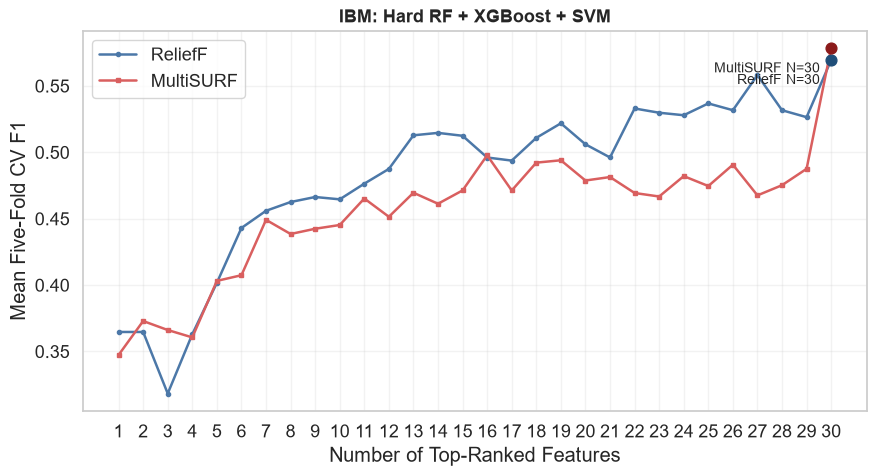

,Feature Selection,CV-Selected Architecture,Selected Features,Peak Mean CV F1
0,ReliefF,Hard RF + XGBoost + SVM,30,0.5695
1,MultiSURF,Hard RF + XGBoost + SVM,30,0.5786


CV-selected architecture used for both curves: Hard RF + XGBoost + SVM
Feature-count rule: choose the smallest N attaining the maximum mean CV F1.
Saved figure: ibm_reviewed_v1_cv_selected_feature_count.png
Saved curve data: ibm_reviewed_v1_cv_selected_feature_count.csv


In [21]:
# CV_SELECTED_SELECTOR_COMPARISON
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

required_objects = ["test_results", "scores", "best_feature_counts", "max_n"]
missing_objects = [name for name in required_objects if name not in globals()]
if missing_objects:
    raise RuntimeError(
        "Run the Top-N feature evaluation and final holdout evaluation first. "
        f"Missing objects: {missing_objects}"
    )


# Match the same architecture under both selectors, chosen by training CV.
winner_model_name = str(selected_configuration["Model"])

for score_key in ("relief", "multi"):
    if winner_model_name not in scores[score_key]:
        raise KeyError(f"Missing feature-count curve for {winner_model_name} in {score_key} scores")

n_values = np.arange(1, max_n + 1)
relief_curve = np.asarray(scores["relief"][winner_model_name], dtype=float)
multisurf_curve = np.asarray(scores["multi"][winner_model_name], dtype=float)
relief_n = best_feature_counts["ReliefF"][winner_model_name]
multisurf_n = best_feature_counts["MultiSURF"][winner_model_name]

curve_data = pd.DataFrame({
    "N Features": n_values,
    "ReliefF Mean CV F1": relief_curve,
    "MultiSURF Mean CV F1": multisurf_curve,
})

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(
    n_values, relief_curve, marker="o", markersize=3, linewidth=1.8,
    color="#4C78A8", label="ReliefF",
)
ax.plot(
    n_values, multisurf_curve, marker="s", markersize=3, linewidth=1.8,
    color="#D95F5F", label="MultiSURF",
)
ax.scatter(relief_n, relief_curve[relief_n - 1], color="#1F4E79", s=60, zorder=4)
ax.scatter(multisurf_n, multisurf_curve[multisurf_n - 1], color="#8B1A1A", s=60, zorder=4)
ax.annotate(
    f"ReliefF N={relief_n}",
    (relief_n, relief_curve[relief_n - 1]),
    xytext=(-8, -10), textcoords="offset points",
    ha="right", va="top", fontsize=10,
)
ax.annotate(
    f"MultiSURF N={multisurf_n}",
    (multisurf_n, multisurf_curve[multisurf_n - 1]),
    xytext=(-8, -10), textcoords="offset points",
    ha="right", va="top", fontsize=10,
)

model_label = winner_model_name.replace(" (equal weights)", "")

ax.set_xlabel("Number of Top-Ranked Features")
ax.set_ylabel("Mean Five-Fold CV F1")
ax.set_title("IBM: " + model_label, fontsize=13, fontweight="bold")
ax.set_xticks(n_values)
ax.grid(alpha=0.25)
ax.legend()
fig.tight_layout()

png_path = "ibm_reviewed_v1_cv_selected_feature_count.png"
csv_path = "ibm_reviewed_v1_cv_selected_feature_count.csv"
fig.savefig(png_path, dpi=300, bbox_inches="tight")
curve_data.to_csv(csv_path, index=False)
plt.show()

selected_points = pd.DataFrame({
    "Feature Selection": ["ReliefF", "MultiSURF"],
    "CV-Selected Architecture": [winner_model_name, winner_model_name],
    "Selected Features": [relief_n, multisurf_n],
    "Peak Mean CV F1": [
        relief_curve[relief_n - 1],
        multisurf_curve[multisurf_n - 1],
    ],
})
display(selected_points.round(4))
print(f"CV-selected architecture used for both curves: {winner_model_name}")
print("Feature-count rule: choose the smallest N attaining the maximum mean CV F1.")
print(f"Saved figure: {png_path}")
print(f"Saved curve data: {csv_path}")


## SHAP Analysis

SHAP model selected by training CV: MultiSURF Hard RF + XGBoost + SVM


,Selected SHAP model
Feature Selection,MultiSURF
Model,Hard RF + XGBoost + SVM
Features,30
CV F1,0.578561


100%|██████████| 100/100 [04:24<00:00,  2.64s/it]


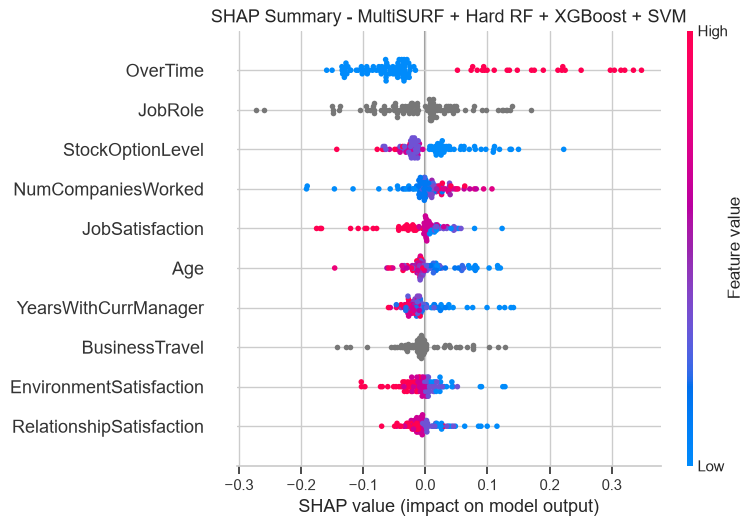

Dependence plots: ['Age', 'JobLevel', 'TotalWorkingYears']


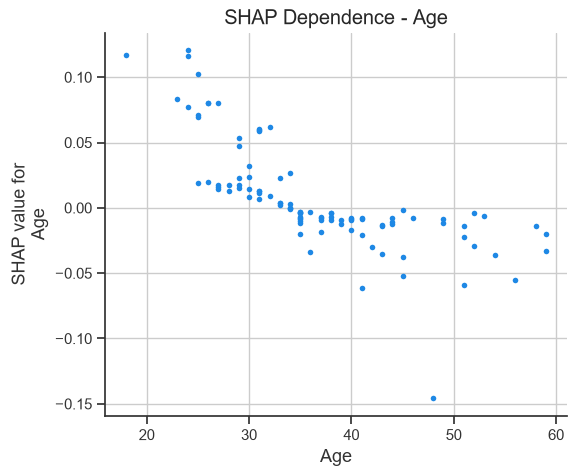

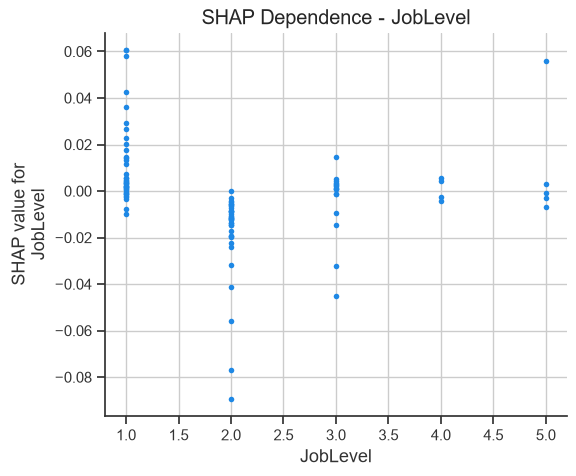

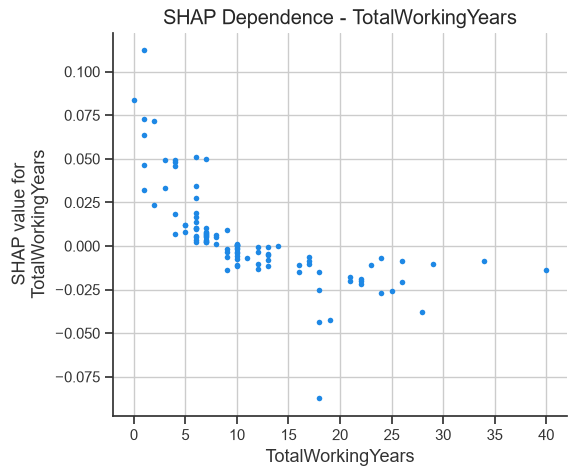

Local explanation: held-out row 1061, actual=0, predicted=0, positive vote fraction=0.3333, SHAP base (positive vote fraction)=0.1467


,Feature,Value,SHAP value
0,BusinessTravel,Non-Travel,-0.1427
1,YearsWithCurrManager,0,0.1379
2,JobRole,Sales Representative,0.1320
3,Age,24,0.1164
4,OverTime,0,-0.1010
5,EnvironmentSatisfaction,4,-0.0721
6,TotalWorkingYears,1,0.0637
7,StockOptionLevel,1,-0.0405
8,YearsInCurrentRole,0,0.0341
9,JobSatisfaction,2,0.0297


,Feature,SMOTE endpoint effect,No-SMOTE endpoint effect,Direction agrees
0,Age,-0.0900,-0.0233,True
1,JobLevel,-0.0333,-0.0133,True
2,TotalWorkingYears,-0.0667,-0.0133,True
3,YearsAtCompany,-0.0200,-0.0267,True
4,YearsInCurrentRole,-0.0733,-0.0200,True
5,YearsSinceLastPromotion,0.0233,0.0167,True
6,YearsWithCurrManager,-0.0933,-0.0333,True


Endpoint effects are sensitivity checks, not causal or cultural effects.


In [22]:
import os
import numpy as np
import pandas as pd
import shap
import matplotlib.pyplot as plt
from sklearn.base import clone


if "selected_configuration" not in globals() or "final_models" not in globals():
    raise RuntimeError("Run the training CV selection and holdout evaluation first.")
shap_selector_name, shap_model_name = selected_key
shap_key = selected_key
fitted_classifier = final_models[shap_key][0].named_steps["clf"]
shap_value_scale = (
    "positive vote fraction" if isinstance(fitted_classifier, VotingClassifier)
    and fitted_classifier.voting == "hard" else "positive-class probability"
)
print("SHAP model selected by training CV:", shap_selector_name, shap_model_name)
display(selected_configuration.to_frame("Selected SHAP model"))

final_pipeline, shap_features = final_models[shap_key]
assert len(shap_features) == best_feature_counts[shap_selector_name][shap_model_name]

shap_smoke = os.environ.get("ATTRITION_SHAP_SMOKE", "0") == "1"
background_size = 10 if shap_smoke else 50
explanation_size = 4 if shap_smoke else 100
coalition_budget = 32 if shap_smoke else 500
background = X_train_raw_model.loc[:, shap_features].sample(
    n=min(background_size, len(X_train_raw_model)), random_state=SEED
)
X_shap_test = X_test_raw_model.loc[:, shap_features].iloc[:explanation_size].copy()

def shap_predict(values):
    frame = values if isinstance(values, pd.DataFrame) else pd.DataFrame(values, columns=shap_features)
    return positive_scores(final_pipeline, frame.loc[:, shap_features])

np.random.seed(SEED)
explainer = shap.KernelExplainer(shap_predict, background)
shap_values = explainer.shap_values(X_shap_test, nsamples=coalition_budget, l1_reg=0.0)
if isinstance(shap_values, list):
    shap_values = shap_values[-1]
shap_values = np.asarray(shap_values)
if shap_values.ndim == 3:
    shap_values = shap_values[:, :, -1]
local_base_value = float(np.asarray(explainer.expected_value).reshape(-1)[-1])

# Global importance summary for the selected model score.
shap.summary_plot(
    shap_values,
    X_shap_test,
    feature_names=shap_features,
    max_display=10,
    show=False,
)
shap_display_name = shap_model_name.replace(" (equal weights)", "")
plt.title(f"SHAP Summary - {shap_selector_name} + {shap_display_name}", fontsize=13)
plt.tight_layout()
plt.savefig(results_dir / "shap_summary.png", dpi=300, bbox_inches="tight")
plt.show()

mean_abs_shap = pd.Series(np.abs(shap_values).mean(axis=0), index=shap_features).sort_values(ascending=False)
seniority_candidates = ['Age', 'JobLevel', 'TotalWorkingYears', 'YearsAtCompany', 'YearsInCurrentRole', 'YearsSinceLastPromotion', 'YearsWithCurrManager']
dependence_features = [f for f in seniority_candidates if f in shap_features]
dependence_features += [f for f in mean_abs_shap.index if f not in dependence_features]
dependence_features = dependence_features[:3]
print("Dependence plots:", dependence_features)
for feature in dependence_features:
    shap.dependence_plot(
        feature,
        shap_values,
        X_shap_test,
        feature_names=shap_features,
        interaction_index=None,
        show=False,
    )
    plt.title(f"SHAP Dependence - {feature}")
    plt.tight_layout()
    plt.show()

# A fixed local case is used instead of selecting a favourable observation.
local_index = 0
local_row_label = X_shap_test.index[local_index]
local_feature_order = np.argsort(np.abs(shap_values[local_index]))[::-1][:10]
local_prediction = positive_scores(final_pipeline, X_shap_test.iloc[[local_index]])[0]
local_class = int(final_pipeline.predict(X_shap_test.iloc[[local_index]])[0])
local_actual = int(y_test.loc[local_row_label])
local_explanation = pd.DataFrame({
    "Feature": [shap_features[i] for i in local_feature_order],
    "Value": [X_shap_test.iloc[local_index, i] for i in local_feature_order],
    "SHAP value": [shap_values[local_index, i] for i in local_feature_order],
})
print(
    f"Local explanation: held-out row {local_row_label}, actual={local_actual}, "
    f"predicted={local_class}, {shap_value_scale}={local_prediction:.4f}, "
    f"SHAP base ({shap_value_scale})={local_base_value:.4f}"
)
display(local_explanation.round(4))

# Sensitivity check: same voting components and features, changing SMOTE only.
seniority_features = [feature for feature in seniority_candidates if feature in shap_features]
if seniority_features:
    no_oversampling_pipeline = build_model_pipeline(clone(model_templates[shap_model_name]), use_smote=False)
    no_oversampling_pipeline.fit(X_train_raw_model.loc[:, shap_features], y_train)
    artifact_rows = []
    for feature in seniority_features:
        low_value, high_value = X_train_raw_model[feature].quantile([0.10, 0.90])
        low_frame = X_shap_test.copy()
        high_frame = X_shap_test.copy()
        low_frame[feature] = low_value
        high_frame[feature] = high_value
        oversampling_effect = np.mean(
            positive_scores(final_pipeline, high_frame)
            - positive_scores(final_pipeline, low_frame)
        )
        no_oversampling_effect = np.mean(
            positive_scores(no_oversampling_pipeline, high_frame)
            - positive_scores(no_oversampling_pipeline, low_frame)
        )
        artifact_rows.append({
            "Feature": feature,
            "SMOTE endpoint effect": oversampling_effect,
            "No-SMOTE endpoint effect": no_oversampling_effect,
            "Direction agrees": np.sign(oversampling_effect) == np.sign(no_oversampling_effect),
        })
    seniority_check = pd.DataFrame(artifact_rows)
    display(seniority_check.round(4))
    print("Endpoint effects are sensitivity checks, not causal or cultural effects.")
else:
    print("No predefined seniority feature is present in this selected subset.")


## Final Model Summary

In [23]:

# Final model summary, selected exclusively by training CV.
print("FINAL MODEL SUMMARY")
display(selected_test_result.to_frame("CV-selected configuration").round(4))
print(f"Holdout F1 95% bootstrap interval: {f1_ci_low:.3f} to {f1_ci_high:.3f}")
print("Matched architecture comparisons:")
display(test_results.pivot(
    index="Model", columns="Feature Selection", values="F1"
).reindex(columns=["All features", "ReliefF", "MultiSURF"]).round(4))
print("Existing holdout comparisons are descriptive. Selection was fixed before holdout evaluation.")


FINAL MODEL SUMMARY


,CV-selected configuration
Feature Selection,MultiSURF
Model,Hard RF + XGBoost + SVM
Features,30
CV F1,0.578561
Accuracy,0.843537
Precision,0.515152
Recall,0.361702
F1,0.425
ROC AUC,0.679645
Average Precision (AP),0.337942


Holdout F1 95% bootstrap interval: 0.282 to 0.556
Matched architecture comparisons:


Feature Selection,All features,ReliefF,MultiSURF
Model,,,
Decision Tree,0.2955,0.4270,0.2955
General Voting,0.3896,0.4156,0.4103
Gradient Boosting,0.3514,0.3014,0.3514
Hard All Five,0.3733,0.3896,0.3947
Hard GB + XGBoost + SVM,0.3784,0.3784,0.3784
Hard RF + GB + XGBoost,0.3514,0.3200,0.3733
Hard RF + XGBoost + SVM,0.4000,0.4359,0.4250
Random Forest,0.4082,0.4255,0.4043
SVM,0.3810,0.3810,0.3810


Existing holdout comparisons are descriptive. Selection was fixed before holdout evaluation.
